# Prediction of residential property prices in France (DVF+)

Exploratory preparation on Paris, followed by nationwide DVF+ analyses and four experiments: model comparison (H1), geographic features (H2), DPE contribution (H3) and temporal validation (H4).

**Reproducibility:** The notebook uses local DVF+ extracts and external ADEME data. Source datasets are not included in this repository. Existing cell outputs are retained as the recorded results of the study; the notebook has not been re-executed during editorial cleanup.

In [2]:
import pandas as pd

file_path = "../data/raw/dvfplus_2014_2024/R11_Ile_de_France/mutations_d75.csv"

df_dvfplus = pd.read_csv(
    file_path,
    sep=";"
)

print("Nombre de lignes :", len(df_dvfplus))
print("Nombre de colonnes :", len(df_dvfplus.columns))

df_dvfplus.head()

Nombre de lignes : 457097
Nombre de colonnes : 58


,idmutation,idmutinvar,idopendata,idnatmut,codservch,refdoc,datemut,anneemut,moismut,coddep,...,sapt3pp,sapt4pp,sapt5pp,smai1pp,smai2pp,smai3pp,smai4pp,smai5pp,codtypbien,libtypbien
0,12720526,b5b875cc3e82afbe1559b1bbeab6157f,b5b875cc3e82afbe1559b1bbeab6157f,2,NaN,NaN,2014-10-30,2014,10,75,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,101,BATI - INDETERMINE : Vefa sans descriptif
1,12738160,120ee7765ec5c132c3ad1394fb4eb803,120ee7765ec5c132c3ad1394fb4eb803,2,NaN,NaN,2014-04-24,2014,4,75,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,101,BATI - INDETERMINE : Vefa sans descriptif
2,12739989,58195de5cc7c8af9065123a10921548e,58195de5cc7c8af9065123a10921548e,2,NaN,NaN,2014-06-06,2014,6,75,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,101,BATI - INDETERMINE : Vefa sans descriptif
3,12614303,cde20196abea7b83aad052292719a392,cde20196abea7b83aad052292719a392,1,NaN,NaN,2015-04-27,2015,4,75,...,61.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,121,UN APPARTEMENT
4,11294682,338481e00e9556bb5035f56ec9016062,338481e00e9556bb5035f56ec9016062,1,NaN,NaN,2024-11-25,2024,11,75,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,21,TERRAIN DE TYPE TAB


In [3]:
for i, colonne in enumerate(df_dvfplus.columns, start=1) : 
    print(i,colonne)

1 idmutation
2 idmutinvar
3 idopendata
4 idnatmut
5 codservch
6 refdoc
7 datemut
8 anneemut
9 moismut
10 coddep
11 libnatmut
12 vefa
13 valeurfonc
14 nbdispo
15 nblot
16 nbcomm
17 l_codinsee
18 nbsection
19 l_section
20 nbpar
21 l_idpar
22 nbparmut
23 l_idparmut
24 nbsuf
25 sterr
26 nbvolmut
27 nblocmut
28 l_idlocmut
29 nblocmai
30 nblocapt
31 nblocdep
32 nblocact
33 nbapt1pp
34 nbapt2pp
35 nbapt3pp
36 nbapt4pp
37 nbapt5pp
38 nbmai1pp
39 nbmai2pp
40 nbmai3pp
41 nbmai4pp
42 nbmai5pp
43 sbati
44 sbatmai
45 sbatapt
46 sbatact
47 sapt1pp
48 sapt2pp
49 sapt3pp
50 sapt4pp
51 sapt5pp
52 smai1pp
53 smai2pp
54 smai3pp
55 smai4pp
56 smai5pp
57 codtypbien
58 libtypbien


In [4]:
df_2024 = df_dvfplus[(df_dvfplus['anneemut'] == 2024) & (df_dvfplus['libnatmut']=="Vente")].copy()

print("Nombre de ventes Paris 2024 :", len(df_2024))
()
df_2024[
    [
        "datemut",
        "valeurfonc",
        "nblocmai",
        "nblocapt",
        "nblocdep",
        "nblocact",
        "sbati",
        "sterr",
        "libtypbien"
    ]
].head(10)


Nombre de ventes Paris 2024 : 35282


,datemut,valeurfonc,nblocmai,nblocapt,nblocdep,nblocact,sbati,sterr,libtypbien
4,2024-11-25,5900283.0,0,0,0,0,0.0,1197.0,TERRAIN DE TYPE TAB
5,2024-07-04,1.0,0,0,0,0,0.0,0.0,BATI - INDETERMINE : Vente avec volume(s)
6,2024-02-23,80000.0,0,1,0,0,8.0,0.0,APPARTEMENT INDETERMINE
7,2024-08-01,774000.0,0,1,0,0,121.0,0.0,UN APPARTEMENT
8,2024-06-14,160000.0,0,1,0,0,20.0,0.0,UN APPARTEMENT
9,2024-09-24,185000.0,0,1,0,0,18.0,0.0,UN APPARTEMENT
10,2024-06-06,2468700.0,0,1,0,0,101.0,0.0,UN APPARTEMENT
11,2024-11-08,160000.0,0,1,0,0,41.0,0.0,UN APPARTEMENT
12,2024-12-20,535000.0,0,0,0,1,76.0,0.0,ACTIVITE
14,2024-08-22,269500.0,0,1,0,0,38.0,0.0,UN APPARTEMENT


In [5]:
# Nombre total de logements principaux dans chaque vente
df_2024["Nombre de logements"] = (
    df_2024["nblocmai"]
    + df_2024["nblocapt"]
)

In [6]:
df_2024["Nombre de logements"].value_counts().sort_index()

Nombre de logements
0       7950
1      25875
2       1110
3        109
4         39
5         25
6         17
7         11
8         12
9          6
10         5
11        11
12         7
13        13
14         4
15         8
16         8
17         3
18         8
19         5
20         4
21         5
22         2
23         5
24         2
25         3
26         2
27         3
28         1
29         1
30         1
31         1
32         2
33         1
34         2
36         1
37         1
38         1
42         1
43         2
45         4
47         1
48         1
66         1
68         1
81         1
90         1
95         1
96         1
97         1
157        1
429        1
Name: count, dtype: int64

Sur les 35 282 ventes Paris 2024 :

0 logement → 7 950 ventes
1 logement → 25 875 ventes
2 logements → 1 110 ventes
puis beaucoup moins pour 3, 4, 5, etc.

Donc notre cœur de dataset potentiel, ce sont les 25 875 ventes avec exactement un logement.

In [7]:
df_residentiel = df_2024[
    df_2024["Nombre de logements"] == 1
].copy()

In [8]:
print("Nombre de ventes résidentielles :", len(df_residentiel))

Nombre de ventes résidentielles : 25875


### Sélection des ventes avec un seul logement

Parmi les 35 282 ventes parisiennes de 2024, 25 875 concernent exactement un logement principal.

Nous conservons ces transactions car la valeur foncière peut alors être rattachée à un seul logement, ce qui est nécessaire pour construire un modèle de prédiction du prix à l’échelle du bien.

In [9]:
df_residentiel = df_2024[
    df_2024["Nombre de logements"] == 1
].copy()

print("Nombre de ventes résidentielles :", len(df_residentiel))

Nombre de ventes résidentielles : 25875


In [10]:
df_residentiel["Type logement"] = df_residentiel["nblocapt"].map({
    1: "Appartement",
    0: "Maison"
})

df_residentiel["Type logement"].value_counts()

Type logement
Appartement    25761
Maison           114
Name: count, dtype: int64

Parmi les 25 875 ventes résidentielles sélectionnées à Paris en 2024, 25 761 concernent un appartement et seulement 114 une maison.

Le dataset parisien est donc très fortement dominé par les appartements. Cette forte asymétrie devra être prise en compte lors de l'interprétation des résultats du modèle, notamment si l'on souhaite généraliser ensuite l'étude à d'autres départements où les maisons sont beaucoup plus représentées.

In [11]:
df_residentiel[
    [
        "valeurfonc",
        "sbati",
        "sbatapt",
        "sbatmai",
        "nblocdep",
        "sterr",
        "libtypbien"
    ]
].head(10)

,valeurfonc,sbati,sbatapt,sbatmai,nblocdep,sterr,libtypbien
6,80000.0,8.0,8.0,0.0,0,0.0,APPARTEMENT INDETERMINE
7,774000.0,121.0,121.0,0.0,0,0.0,UN APPARTEMENT
8,160000.0,20.0,20.0,0.0,0,0.0,UN APPARTEMENT
9,185000.0,18.0,18.0,0.0,0,0.0,UN APPARTEMENT
10,2468700.0,101.0,101.0,0.0,0,0.0,UN APPARTEMENT
11,160000.0,41.0,41.0,0.0,0,0.0,UN APPARTEMENT
14,269500.0,38.0,38.0,0.0,0,0.0,UN APPARTEMENT
15,930000.0,55.0,55.0,0.0,0,0.0,UN APPARTEMENT
19,376660.0,40.0,40.0,0.0,0,0.0,UN APPARTEMENT
21,697000.0,58.0,58.0,0.0,0,0.0,UN APPARTEMENT


Observation des caractéristiques physiques des ventes résidentielles : 

Les variables DVF+ permettent de récupérer directement plusieurs caractéristiques physiques des transactions : surface bâtie totale (sbati), surface des appartements (sbatapt), surface des maisons (sbatmai), nombre de dépendances (nblocdep) et surface de terrain (sterr).

Sur les premières observations, principalement constituées d'appartements, la surface bâtie totale correspond à la surface des appartements tandis que la surface des maisons est nulle.

In [12]:
df_residentiel["nblocact"].value_counts().sort_index()

nblocact
0     25503
1       335
2        22
3         7
4         1
5         1
8         1
10        2
11        1
20        1
25        1
Name: count, dtype: int64

##### Exclusion des ventes mixtes avec locaux d'activité

Parmi les 25 875 ventes contenant exactement un logement principal, 25 503 ne comportent aucun local d'activité.

372 transactions contiennent également un ou plusieurs locaux d'activité. Ces ventes sont exclues car la valeur foncière correspond au prix global de la transaction et ne peut pas être attribuée uniquement au logement résidentiel.

In [13]:
df_residentiel_pur = df_residentiel[
    df_residentiel["nblocact"] == 0
].copy()

print(
    "Nombre de ventes résidentielles pures :",
    len(df_residentiel_pur)
)

Nombre de ventes résidentielles pures : 25503


Les dépendances (nblocdep) restent autorisées : cave, parking, garage, etc. peuvent faire partie normalement de la vente du logement.

Constitution du sous-échantillon résidentiel pur

Après exclusion des transactions contenant un local d'activité, le dataset contient 25 503 ventes résidentielles pures à Paris en 2024.

Chaque transaction comporte exactement un logement principal, éventuellement accompagné de dépendances, mais aucun local d'activité. Ce sous-échantillon constitue la base retenue pour la préparation des variables du modèle.

### Construction de la surface habitable

In [14]:
df_residentiel_pur["Surface logement"] = (
    df_residentiel_pur["sbatapt"]
    + df_residentiel_pur["sbatmai"]
)

In [15]:
df_residentiel_pur[
    [
        "Type logement",
        "sbatapt",
        "sbatmai",
        "Surface logement",
        "valeurfonc"
    ]
].head(10)

,Type logement,sbatapt,sbatmai,Surface logement,valeurfonc
6,Appartement,8.0,0.0,8.0,80000.0
7,Appartement,121.0,0.0,121.0,774000.0
8,Appartement,20.0,0.0,20.0,160000.0
9,Appartement,18.0,0.0,18.0,185000.0
10,Appartement,101.0,0.0,101.0,2468700.0
11,Appartement,41.0,0.0,41.0,160000.0
14,Appartement,38.0,0.0,38.0,269500.0
15,Appartement,55.0,0.0,55.0,930000.0
19,Appartement,40.0,0.0,40.0,376660.0
21,Appartement,58.0,0.0,58.0,697000.0


Création de la surface du logement

Une variable unique `Surface logement` est créée à partir des surfaces spécifiques aux appartements (`sbatapt`) et aux maisons (`sbatmai`).

Comme chaque transaction retenue contient exactement un logement principal, cette variable permet de disposer d'une seule mesure de surface utilisable par le modèle, quel que soit le type de logement.

### Reconstruction du nombre de pièces

In [16]:
df_residentiel_pur["Nombre pieces"] = (
    1 * (df_residentiel_pur["nbapt1pp"] + df_residentiel_pur["nbmai1pp"])
    + 2 * (df_residentiel_pur["nbapt2pp"] + df_residentiel_pur["nbmai2pp"])
    + 3 * (df_residentiel_pur["nbapt3pp"] + df_residentiel_pur["nbmai3pp"])
    + 4 * (df_residentiel_pur["nbapt4pp"] + df_residentiel_pur["nbmai4pp"])
    + 5 * (df_residentiel_pur["nbapt5pp"] + df_residentiel_pur["nbmai5pp"])
)

In [17]:
df_residentiel_pur["Nombre pieces"].value_counts().sort_index()

Nombre pieces
0       2
1    7215
2    8652
3    5371
4    2564
5    1699
Name: count, dtype: int64

Création du nombre de pièces principales

Le nombre de pièces principales est reconstruit à partir des variables DVF+ décrivant les appartements et maisons de 1 à 5 pièces ou plus.

La majorité des logements comportent entre 1 et 3 pièces. Seulement deux transactions ont une valeur égale à 0, ce qui indique que l'information sur le nombre de pièces n'est pas renseignée pour ces cas.

La valeur 5 regroupe les logements comportant cinq pièces principales ou davantage.

In [18]:
df_residentiel_pur = df_residentiel_pur[
    df_residentiel_pur["Nombre pieces"] > 0
].copy()

print("Nombre de ventes restantes :", len(df_residentiel_pur))

Nombre de ventes restantes : 25501


### Contrôle des surfaces

In [19]:
print("Surfaces manquantes :", df_residentiel_pur["Surface logement"].isna().sum())
print("Surfaces <= 0 :", (df_residentiel_pur["Surface logement"] <= 0).sum())

df_residentiel_pur["Surface logement"].describe(
    percentiles=[0.01, 0.05, 0.95, 0.99]
)

Surfaces manquantes : 0
Surfaces <= 0 : 0


count    25501.000000
mean        52.579546
std         39.911477
min          4.000000
1%           9.000000
5%          14.000000
95%        125.000000
99%        199.000000
max       1500.000000
Name: Surface logement, dtype: float64

Les 25 501 transactions disposent toutes d'une surface strictement positive. La surface médiane est de 39 m² et 99 % des logements ont une surface inférieure ou égale à 199 m².

Quelques valeurs très élevées existent, avec un maximum de 1 500 m². Elles sont conservées à ce stade afin de ne pas appliquer de règle d'exclusion arbitraire avant l'évaluation des premiers modèles.

In [20]:
colonnes_ml = [
    "valeurfonc",
    "Surface logement",
    "Nombre pieces",
    "Type logement",
    "nblocdep",
    "sterr",
    "l_codinsee",
    "datemut"
]

df_ml = df_residentiel_pur[colonnes_ml].copy()

df_ml.head()

,valeurfonc,Surface logement,Nombre pieces,Type logement,nblocdep,sterr,l_codinsee,datemut
6,80000.0,8.0,1,Appartement,0,0.0,['75111'],2024-02-23
7,774000.0,121.0,5,Appartement,0,0.0,['75120'],2024-08-01
8,160000.0,20.0,1,Appartement,0,0.0,['75102'],2024-06-14
9,185000.0,18.0,1,Appartement,0,0.0,['75111'],2024-09-24
10,2468700.0,101.0,2,Appartement,0,0.0,['75108'],2024-06-06


Un sous-ensemble des variables pertinentes est conservé pour la modélisation : prix de vente, surface du logement, nombre de pièces, type de logement, dépendances, surface de terrain, localisation et date de mutation.

La variable `valeurfonc` constituera la cible à prédire, tandis que les autres variables serviront de caractéristiques explicatives du modèle.

### Types et valeurs manquantes

In [21]:
print(df_ml.dtypes)

print("\nValeurs manquantes :")
print(df_ml.isna().sum())

valeurfonc          float64
Surface logement    float64
Nombre pieces         int64
Type logement           str
nblocdep              int64
sterr               float64
l_codinsee              str
datemut                 str
dtype: object

Valeurs manquantes :
valeurfonc          7
Surface logement    0
Nombre pieces       0
Type logement       0
nblocdep            0
sterr               0
l_codinsee          0
datemut             0
dtype: int64


Le contrôle des types et des valeurs manquantes montre que les variables explicatives sont complètes. Seules 7 transactions ne disposent pas de valeur foncière.

Comme la valeur foncière constitue la cible à prédire, ces observations ne peuvent pas être utilisées pour l'apprentissage supervisé et sont donc retirées. La date de mutation est également convertie au format temporel afin de pouvoir être utilisée ultérieurement pour les analyses temporelles.

In [22]:
# On retire les ventes pour lesquelles le prix à prédire est absent
df_ml = df_ml.dropna(subset=["valeurfonc"]).copy()

# On convertit la date en vrai format datetime
df_ml["datemut"] = pd.to_datetime(df_ml["datemut"])

print("Nombre de ventes restantes :", len(df_ml))
print("\nTypes après correction :")
print(df_ml.dtypes)

Nombre de ventes restantes : 25494

Types après correction :
valeurfonc                 float64
Surface logement           float64
Nombre pieces                int64
Type logement                  str
nblocdep                     int64
sterr                      float64
l_codinsee                     str
datemut             datetime64[us]
dtype: object


Après suppression des 7 transactions dont la valeur foncière était absente, le dataset contient 25 494 ventes résidentielles exploitables.

La date de mutation a également été convertie au format temporel (`datetime`), ce qui permettra notamment de réaliser ultérieurement une séparation chronologique des données.

In [23]:
y = df_ml["valeurfonc"]

X = df_ml[
    [
        "Surface logement",
        "Nombre pieces",
        "Type logement",
        "nblocdep",
        "sterr"
    ]
].copy()

In [24]:
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

X.head()

Dimensions de X : (25494, 5)
Dimensions de y : (25494,)


,Surface logement,Nombre pieces,Type logement,nblocdep,sterr
6,8.0,1,Appartement,0,0.0
7,121.0,5,Appartement,0,0.0
8,20.0,1,Appartement,0,0.0
9,18.0,1,Appartement,0,0.0
10,101.0,2,Appartement,0,0.0


##### Définition des variables explicatives et de la cible

La variable cible `y` correspond à la valeur foncière de chaque transaction, c'est-à-dire au prix que le modèle devra prédire.

Les variables explicatives `X` décrivent les caractéristiques physiques du logement : surface, nombre de pièces, type de logement, nombre de dépendances et surface de terrain.

Le dataset contient 25 494 observations et 5 variables explicatives. La localisation est volontairement exclue de cette première configuration afin de construire une référence basée uniquement sur les caractéristiques physiques du bien. Elle sera ajoutée ultérieurement pour mesurer son apport sur les performances.

In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train :", X_train.shape)
print("X_test :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

X_train : (20395, 5)
X_test : (5099, 5)
y_train : (20395,)
y_test : (5099,)


Les 25 494 transactions sont séparées aléatoirement en deux ensembles :

- 80 % des observations (20 395 ventes) sont utilisées pour entraîner les modèles ;
- 20 % des observations (5 099 ventes) sont conservées pour évaluer leurs performances sur des transactions jamais vues pendant l'apprentissage.

Le paramètre `random_state=42` permet de reproduire exactement la même séparation lors de futures exécutions.

In [29]:
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Prix médian observé uniquement sur les données d'entraînement
prix_median_train = y_train.median()

# La baseline prédit ce même prix pour toutes les ventes du test
y_pred_baseline = np.full(
    len(y_test),
    prix_median_train
)

mae_baseline = mean_absolute_error(y_test, y_pred_baseline)

rmse_baseline = np.sqrt(
    mean_squared_error(y_test, y_pred_baseline)
)

r2_baseline = r2_score(y_test, y_pred_baseline)

print("Prix médian du train :", prix_median_train)
print("MAE baseline :", mae_baseline)
print("RMSE baseline :", rmse_baseline)
print("R² baseline :", r2_baseline)

Prix médian du train : 375000.0
MAE baseline : 330021.8448146696
RMSE baseline : 720321.813701635
R² baseline : -0.0650852086242113


Une première référence est construite en prédisant, pour chaque transaction du jeu de test, le prix médian observé dans le jeu d'entraînement, soit 375 000 €.

Cette stratégie naïve obtient une MAE d'environ 330 000 € et une RMSE d'environ 720 000 €. Le R² est négatif (-0,065), ce qui confirme que cette méthode n'explique pas la variabilité des prix immobiliers.

Cette baseline constitue désormais le niveau minimal de performance que les modèles de Machine Learning devront dépasser.

In [30]:
variables_numeriques = [
    "Surface logement",
    "Nombre pieces",
    "nblocdep",
    "sterr"
]

X_num = df_ml[variables_numeriques].copy()

X_train_num, X_test_num, y_train, y_test = train_test_split(
    X_num,
    y,
    test_size=0.20,
    random_state=42
)

In [31]:
from sklearn.linear_model import LinearRegression

modele_lineaire = LinearRegression()

modele_lineaire.fit(
    X_train_num,
    y_train
)

y_pred_lineaire = modele_lineaire.predict(X_test_num)

In [32]:
# Et mesurer :

mae_lineaire = mean_absolute_error(y_test, y_pred_lineaire)

rmse_lineaire = np.sqrt(
    mean_squared_error(y_test, y_pred_lineaire)
)

r2_lineaire = r2_score(y_test, y_pred_lineaire)

print("MAE régression linéaire :", mae_lineaire)
print("RMSE régression linéaire :", rmse_lineaire)
print("R² régression linéaire :", r2_lineaire)

MAE régression linéaire : 170934.82646504746
RMSE régression linéaire : 406711.71913522854
R² régression linéaire : 0.6604493291869733


Une première régression linéaire est entraînée à partir des caractéristiques physiques des logements : surface, nombre de pièces, dépendances et surface de terrain.

Le modèle obtient une MAE d'environ 171 000 €, contre environ 330 000 € pour la baseline naïve. L'erreur moyenne est donc fortement réduite.

Le coefficient R² atteint environ 0,66, ce qui montre que les caractéristiques physiques du logement expliquent déjà une part importante de la variabilité des prix, même sans information géographique.

In [33]:
X_encoded = pd.get_dummies(
    X,
    columns=["Type logement"],
    drop_first=True
)

X_encoded.head()

,Surface logement,Nombre pieces,nblocdep,sterr,Type logement_Maison
6,8.0,1,0,0.0,False
7,121.0,5,0,0.0,False
8,20.0,1,0,0.0,False
9,18.0,1,0,0.0,False
10,101.0,2,0,0.0,False


Encodage du type de logement

La variable catégorielle `Type logement` est transformée en variable numérique grâce au one-hot encoding.

La nouvelle variable `Type logement_Maison` vaut `True` pour une maison et `False` pour un appartement. Cette transformation permet d'intégrer le type de logement dans les modèles de Machine Learning.

In [34]:
X_train_encoded, X_test_encoded, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42
)

modele_lineaire_type = LinearRegression()

modele_lineaire_type.fit(
    X_train_encoded,
    y_train
)

y_pred_lineaire_type = modele_lineaire_type.predict(
    X_test_encoded
)

In [35]:
# Puis les métriques
mae_lineaire_type = mean_absolute_error(
    y_test,
    y_pred_lineaire_type
)

rmse_lineaire_type = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_lineaire_type
    )
)

r2_lineaire_type = r2_score(
    y_test,
    y_pred_lineaire_type
)

print("MAE :", mae_lineaire_type)
print("RMSE :", rmse_lineaire_type)
print("R² :", r2_lineaire_type)

MAE : 170821.7802935072
RMSE : 406145.64696632983
R² : 0.6613938626932487


Ajout du type de logement à la régression linéaire : 

L'ajout du type de logement améliore très légèrement les performances de la régression linéaire.

La MAE passe d'environ 170 935 € à 170 822 €, tandis que le R² augmente de 0,660 à 0,661.

Cette amélioration très faible s'explique notamment par la forte domination des appartements dans le dataset parisien : le type de logement apporte donc peu d'information discriminante supplémentaire dans cet échantillon.

In [36]:
from sklearn.ensemble import RandomForestRegressor

modele_rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

modele_rf.fit(
    X_train_encoded,
    y_train
)

y_pred_rf = modele_rf.predict(
    X_test_encoded
)

In [37]:
# Puis les métriques : 
mae_rf = mean_absolute_error(
    y_test,
    y_pred_rf
)

rmse_rf = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_rf
    )
)

r2_rf = r2_score(
    y_test,
    y_pred_rf
)

print("MAE Random Forest :", mae_rf)
print("RMSE Random Forest :", rmse_rf)
print("R² Random Forest :", r2_rf)

MAE Random Forest : 163748.7759737474
RMSE Random Forest : 405331.6346620528
R² Random Forest : 0.6627497967065108


##### Modèle Random Forest

Le modèle Random Forest obtient une MAE d'environ 164 000 €, contre environ 171 000 € pour la régression linéaire.

Le modèle non linéaire améliore donc les prédictions, mais le gain reste relativement limité. Le R² reste proche de 0,66, ce qui suggère que les caractéristiques physiques seules ne suffisent probablement pas à expliquer davantage la variabilité des prix immobiliers.

Cette observation renforce notamment l'intérêt de tester ultérieurement l'apport des variables géographiques.

C’est particulièrement important parce que mon hypothèse H1 suppose que les méthodes de Gradient Boosting devraient mieux performer que les modèles plus simples.

On garde exactement le même train/test pour que la comparaison soit juste.

In [38]:
from sklearn.ensemble import GradientBoostingRegressor

modele_gb = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

modele_gb.fit(
    X_train_encoded,
    y_train
)

y_pred_gb = modele_gb.predict(
    X_test_encoded
)

In [39]:
mae_gb = mean_absolute_error(
    y_test,
    y_pred_gb
)

rmse_gb = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_gb
    )
)

r2_gb = r2_score(
    y_test,
    y_pred_gb
)

print("MAE Gradient Boosting :", mae_gb)
print("RMSE Gradient Boosting :", rmse_gb)
print("R² Gradient Boosting :", r2_gb)

MAE Gradient Boosting : 153030.5656042477
RMSE Gradient Boosting : 399862.3552257746
R² Gradient Boosting : 0.6717896598839088


##### Modèle Gradient Boosting

Le Gradient Boosting obtient les meilleures performances parmi les modèles testés jusqu'à présent, avec une MAE d'environ 153 000 €, une RMSE d'environ 400 000 € et un R² de 0,672.

Il améliore les résultats obtenus par la régression linéaire et le Random Forest. Ces premiers résultats soutiennent donc provisoirement l'hypothèse H1 selon laquelle une méthode de boosting est mieux adaptée à la prédiction des prix immobiliers que des approches plus simples.

Cette conclusion reste toutefois préliminaire, car l'expérience porte pour l'instant uniquement sur les ventes parisiennes de 2024 et sur les caractéristiques physiques des logements.

## Comparaison des modèles

In [40]:
resultats_modeles = pd.DataFrame({
    "Modèle": [
        "Baseline naïve",
        "Régression linéaire",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae_baseline,
        mae_lineaire_type,
        mae_rf,
        mae_gb
    ],
    "RMSE": [
        rmse_baseline,
        rmse_lineaire_type,
        rmse_rf,
        rmse_gb
    ],
    "R2": [
        r2_baseline,
        r2_lineaire_type,
        r2_rf,
        r2_gb
    ]
})

resultats_modeles.sort_values("MAE")

,Modèle,MAE,RMSE,R2
3,Gradient Boosting,153030.565604,399862.355226,0.671790
2,Random Forest,163748.775974,405331.634662,0.662750
1,Régression linéaire,170821.780294,406145.646966,0.661394
0,Baseline naïve,330021.844815,720321.813702,-0.065085


Les quatre approches sont évaluées sur exactement le même jeu de test.

Le Gradient Boosting obtient les meilleures performances avec une MAE d'environ 153 000 € et un R² de 0,672. Il devance le Random Forest, puis la régression linéaire, tandis que la baseline naïve reste nettement moins performante.

Ces premiers résultats soutiennent provisoirement l'hypothèse H1 selon laquelle les méthodes de boosting sont mieux adaptées à la prédiction des prix immobiliers que les approches plus simples.

## H2 : ajouter la géographie
On ne l'ajoute pas directement. D'abord on regarde ce que contient réellement l_codinsee à Paris :

In [41]:
print(
    "Nombre de valeurs géographiques différentes :",
    df_ml["l_codinsee"].nunique()
)

df_ml["l_codinsee"].value_counts().head(20)

Nombre de valeurs géographiques différentes : 27


l_codinsee
['75115']    2694
['75118']    2492
['75117']    2205
['75111']    2113
['75116']    1997
['75120']    1716
['75112']    1406
['75114']    1369
['75119']    1355
['75113']    1316
['75110']    1283
['75109']     984
['75105']     784
['75107']     780
['75106']     751
['75108']     595
['75103']     570
['75104']     473
['75102']     347
['75101']     257
Name: count, dtype: int64

#### Analyse de la variable géographique

La variable `l_codinsee` permet d'identifier la localisation des transactions. Dans le dataset parisien, 27 modalités différentes sont observées, dont les codes correspondant aux différents arrondissements de Paris.

Cette variable va être ajoutée aux caractéristiques du logement afin de mesurer l'apport de la localisation sur les performances prédictives. Cette expérience permet de tester l'hypothèse H2 selon laquelle la géographie constitue un déterminant important du prix immobilier.

In [42]:
X_geo = df_ml[
    [
        "Surface logement",
        "Nombre pieces",
        "Type logement",
        "nblocdep",
        "sterr",
        "l_codinsee"
    ]
].copy()

In [43]:
# Puis on transforme les deux variables catégorielles en colonnes numériques :
X_geo_encoded = pd.get_dummies(
    X_geo,
    columns=[
        "Type logement",
        "l_codinsee"
    ],
    drop_first=True
)

print("Nombre de variables avant géographie :", X_encoded.shape[1])
print("Nombre de variables avec géographie :", X_geo_encoded.shape[1])

X_geo_encoded.head()

Nombre de variables avant géographie : 5
Nombre de variables avec géographie : 31


,Surface logement,Nombre pieces,nblocdep,sterr,Type logement_Maison,l_codinsee_['75102'],l_codinsee_['75103'],l_codinsee_['75104'],"l_codinsee_['75105', '75113']",l_codinsee_['75105'],...,l_codinsee_['75112'],l_codinsee_['75113'],l_codinsee_['75114'],l_codinsee_['75115'],l_codinsee_['75116'],"l_codinsee_['75117', '75118']",l_codinsee_['75117'],l_codinsee_['75118'],l_codinsee_['75119'],l_codinsee_['75120']
6,8.0,1,0,0.0,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
7,121.0,5,0,0.0,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
8,20.0,1,0,0.0,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9,18.0,1,0,0.0,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
10,101.0,2,0,0.0,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


#### Encodage de la localisation

La variable géographique `l_codinsee` est transformée par one-hot encoding afin de pouvoir être utilisée par les modèles.

Le nombre de variables explicatives passe ainsi de 5 à 31. Chaque zone géographique est représentée par une variable binaire indiquant si la transaction appartient ou non à cette zone.

Cette nouvelle configuration permettra de mesurer précisément l'apport de la localisation par rapport au modèle basé uniquement sur les caractéristiques physiques.

In [44]:
X_train_geo, X_test_geo, y_train, y_test = train_test_split(
    X_geo_encoded,
    y,
    test_size=0.20,
    random_state=42
)

modele_gb_geo = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

modele_gb_geo.fit(
    X_train_geo,
    y_train
)

y_pred_gb_geo = modele_gb_geo.predict(
    X_test_geo
)

In [45]:
mae_gb_geo = mean_absolute_error(
    y_test,
    y_pred_gb_geo
)

rmse_gb_geo = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_gb_geo
    )
)

r2_gb_geo = r2_score(
    y_test,
    y_pred_gb_geo
)

print("MAE Gradient Boosting + géographie :", mae_gb_geo)
print("RMSE Gradient Boosting + géographie :", rmse_gb_geo)
print("R² Gradient Boosting + géographie :", r2_gb_geo)

MAE Gradient Boosting + géographie : 140268.81111322762
RMSE Gradient Boosting + géographie : 379770.7791967709
R² Gradient Boosting + géographie : 0.7039436973364239


### Apport de la géographie

L'ajout de la localisation améliore nettement les performances du Gradient Boosting.

La MAE passe d'environ 153 000 € sans information géographique à environ 140 000 € avec la localisation. Le R² progresse également de 0,672 à 0,704.

Ces résultats soutiennent l'hypothèse H2 : à caractéristiques physiques identiques, la localisation constitue une information importante pour prédire la valeur d'un bien immobilier.

In [46]:
resultats_modeles = pd.DataFrame({
    "Modèle": [
        "Baseline naïve",
        "Régression linéaire",
        "Random Forest",
        "Gradient Boosting",
        "Gradient Boosting + géographie"
    ],
    "MAE": [
        mae_baseline,
        mae_lineaire_type,
        mae_rf,
        mae_gb,
        mae_gb_geo
    ],
    "RMSE": [
        rmse_baseline,
        rmse_lineaire_type,
        rmse_rf,
        rmse_gb,
        rmse_gb_geo
    ],
    "R2": [
        r2_baseline,
        r2_lineaire_type,
        r2_rf,
        r2_gb,
        r2_gb_geo
    ]
})

resultats_modeles.sort_values("MAE")

,Modèle,MAE,RMSE,R2
4,Gradient Boosting + géographie,140268.811113,379770.779197,0.703944
3,Gradient Boosting,153030.565604,399862.355226,0.671790
2,Random Forest,163748.775974,405331.634662,0.662750
1,Régression linéaire,170821.780294,406145.646966,0.661394
0,Baseline naïve,330021.844815,720321.813702,-0.065085


#### Synthèse des performances sur Paris en 2024

La comparaison des modèles montre une amélioration progressive des performances par rapport à la baseline naïve.

Le Gradient Boosting obtient les meilleurs résultats parmi les modèles utilisant uniquement les caractéristiques du bien. L'ajout de la localisation améliore encore les performances : la MAE atteint environ 140 000 € et le R² 0,704.

Ces résultats préliminaires soutiennent deux hypothèses de recherche :

- H1 : les méthodes de Gradient Boosting sont plus performantes que les modèles plus simples ;
- H2 : l'ajout de l'information géographique améliore significativement la prédiction du prix.

Ces conclusions restent provisoires car elles reposent uniquement sur les transactions parisiennes de 2024.

In [47]:
from pathlib import Path

dossier_dvfplus = Path(
    "../data/raw/dvfplus_2014_2024"
)

fichiers_departements = list(
    dossier_dvfplus.rglob("mutations_d*.csv")
)

print(
    "Nombre de fichiers départementaux :",
    len(fichiers_departements)
)

fichiers_departements[:10]

Nombre de fichiers départementaux : 97


[WindowsPath('../data/raw/dvfplus_2014_2024/R01_Guadeloupe/mutations_d971.csv'),
 WindowsPath('../data/raw/dvfplus_2014_2024/R02_Martinique/mutations_d972.csv'),
 WindowsPath('../data/raw/dvfplus_2014_2024/R03_Guyane/mutations_d973.csv'),
 WindowsPath('../data/raw/dvfplus_2014_2024/R04_La_Reunion/mutations_d974.csv'),
 WindowsPath('../data/raw/dvfplus_2014_2024/R11_Ile_de_France/mutations_d75.csv'),
 WindowsPath('../data/raw/dvfplus_2014_2024/R11_Ile_de_France/mutations_d77.csv'),
 WindowsPath('../data/raw/dvfplus_2014_2024/R11_Ile_de_France/mutations_d78.csv'),
 WindowsPath('../data/raw/dvfplus_2014_2024/R11_Ile_de_France/mutations_d91.csv'),
 WindowsPath('../data/raw/dvfplus_2014_2024/R11_Ile_de_France/mutations_d92.csv'),
 WindowsPath('../data/raw/dvfplus_2014_2024/R11_Ile_de_France/mutations_d93.csv')]

#### Passage du prototype parisien à l'échelle nationale

Le répertoire DVF+ contient 97 fichiers départementaux exploitables.

Le pipeline développé et validé sur Paris peut maintenant être appliqué à l'ensemble de ces fichiers. Afin de limiter l'utilisation de la mémoire, chaque fichier sera chargé séparément en ne conservant que les variables utiles et les transactions de l'année 2024.

In [48]:
colonnes_utiles_france = [
    "datemut",
    "anneemut",
    "libnatmut",
    "coddep",
    "l_codinsee",
    "valeurfonc",
    "nblocmai",
    "nblocapt",
    "nblocdep",
    "nblocact",
    "sbatapt",
    "sbatmai",
    "sterr",
    "nbapt1pp",
    "nbapt2pp",
    "nbapt3pp",
    "nbapt4pp",
    "nbapt5pp",
    "nbmai1pp",
    "nbmai2pp",
    "nbmai3pp",
    "nbmai4pp",
    "nbmai5pp"
]

In [49]:
ventes_2024_par_departement = []

for fichier in fichiers_departements:

    df_dep = pd.read_csv(
        fichier,
        sep=";",
        usecols=colonnes_utiles_france
    )

    df_dep = df_dep[
        (df_dep["anneemut"] == 2024)
        & (df_dep["libnatmut"] == "Vente")
    ]

    ventes_2024_par_departement.append(df_dep)

df_france_2024 = pd.concat(
    ventes_2024_par_departement,
    ignore_index=True
)

print(
    "Nombre de ventes France 2024 :",
    len(df_france_2024)
)

df_france_2024.head()

Nombre de ventes France 2024 : 1129669


,datemut,anneemut,coddep,libnatmut,valeurfonc,l_codinsee,sterr,nblocmai,nblocapt,nblocdep,...,nbapt3pp,nbapt4pp,nbapt5pp,nbmai1pp,nbmai2pp,nbmai3pp,nbmai4pp,nbmai5pp,sbatmai,sbatapt
0,2024-05-17,2024,971,Vente,1705100.0,['97123'],1003.0,0,0,0,...,0,0,0,0,0,0,0,0,0.0,0.0
1,2024-09-26,2024,971,Vente,97345.0,['97115'],437.0,0,0,0,...,0,0,0,0,0,0,0,0,0.0,0.0
2,2024-09-20,2024,971,Vente,8000.0,['97101'],422.0,0,0,0,...,0,0,0,0,0,0,0,0,0.0,0.0
3,2024-07-19,2024,971,Vente,126500.0,['97125'],978.0,0,0,0,...,0,0,0,0,0,0,0,0,0.0,0.0
4,2024-12-23,2024,971,Vente,79000.0,['97117'],557.0,0,0,0,...,0,0,0,0,0,0,0,0,0.0,0.0


##### Constitution du dataset national DVF+ 2024

Les 97 fichiers départementaux DVF+ ont été parcourus afin de récupérer uniquement les mutations de nature `Vente` réalisées en 2024.

Après concaténation des données départementales, le dataset national contient 1 129 669 ventes. Cette base constitue désormais le point de départ pour appliquer à l'échelle nationale le pipeline de sélection résidentielle précédemment validé sur Paris.

In [50]:
# Nombre de logements principaux présents dans chaque vente
df_france_2024["Nombre de logements"] = (
    df_france_2024["nblocmai"]
    + df_france_2024["nblocapt"]
)

# Répartition avant filtrage
df_france_2024["Nombre de logements"].value_counts().sort_index().head(15)

Nombre de logements
0     359850
1     723545
2      30705
3       6821
4       3277
5       1668
6       1103
7        610
8        462
9        287
10       195
11       158
12       128
13        94
14        55
Name: count, dtype: int64

##### Répartition du nombre de logements à l'échelle nationale

Parmi les ventes DVF+ enregistrées en France en 2024, 723 545 transactions concernent exactement un logement principal.

Ces transactions constituent le sous-ensemble pertinent pour notre modèle, car leur valeur foncière peut être associée à un seul logement. Les ventes sans logement ou comprenant plusieurs logements sont écartées afin d'éviter d'attribuer un prix global à plusieurs biens différents.

In [51]:
df_france_residentiel = df_france_2024[
    df_france_2024["Nombre de logements"] == 1
].copy()

print(
    "Nombre de ventes avec exactement un logement :",
    len(df_france_residentiel)
)

Nombre de ventes avec exactement un logement : 723545


In [52]:
df_france_residentiel[
    "nblocact"
].value_counts().sort_index()

nblocact
0     709820
1      11977
2       1308
3        241
4         85
5         33
6         22
7          7
8          9
9          7
10         3
11         4
12         4
13         3
14         4
16         4
18         2
19         2
20         2
22         1
25         1
27         1
28         1
32         1
34         1
41         1
80         1
Name: count, dtype: int64

#### Exclusion des ventes mixtes à l'échelle nationale

Parmi les 723 545 ventes contenant exactement un logement principal, 709 820 ne comportent aucun local d'activité.

Les autres transactions associent le logement à un ou plusieurs locaux d'activité. Elles sont exclues car la valeur foncière correspond au prix global de la transaction et ne peut pas être attribuée uniquement au logement résidentiel.

In [53]:
df_france_residentiel_pur = df_france_residentiel[
    df_france_residentiel["nblocact"] == 0
].copy()

print(
    "Nombre de ventes résidentielles pures France 2024 :",
    len(df_france_residentiel_pur)
)

Nombre de ventes résidentielles pures France 2024 : 709820


##### Constitution du dataset résidentiel national

Après exclusion des ventes comprenant plusieurs logements ou des locaux d'activité, 709 820 transactions résidentielles pures sont conservées.

Chaque transaction contient exactement un logement principal, éventuellement accompagné de dépendances. Ce sous-ensemble constitue la base nationale utilisée pour reconstruire les caractéristiques du logement avant la modélisation.

In [54]:
# Type du logement
df_france_residentiel_pur["Type logement"] = (
    df_france_residentiel_pur["nblocapt"]
    .map({
        1: "Appartement",
        0: "Maison"
    })
)

# Surface du logement
df_france_residentiel_pur["Surface logement"] = (
    df_france_residentiel_pur["sbatapt"]
    + df_france_residentiel_pur["sbatmai"]
)

# Nombre de pièces principales
df_france_residentiel_pur["Nombre pieces"] = (
    1 * (df_france_residentiel_pur["nbapt1pp"] + df_france_residentiel_pur["nbmai1pp"])
    + 2 * (df_france_residentiel_pur["nbapt2pp"] + df_france_residentiel_pur["nbmai2pp"])
    + 3 * (df_france_residentiel_pur["nbapt3pp"] + df_france_residentiel_pur["nbmai3pp"])
    + 4 * (df_france_residentiel_pur["nbapt4pp"] + df_france_residentiel_pur["nbmai4pp"])
    + 5 * (df_france_residentiel_pur["nbapt5pp"] + df_france_residentiel_pur["nbmai5pp"])
)

In [55]:
# Puis contrôle rapide : 

print(df_france_residentiel_pur["Type logement"].value_counts())

print("\nNombre de pièces :")
print(
    df_france_residentiel_pur["Nombre pieces"]
    .value_counts()
    .sort_index()
)

print(
    "\nSurfaces <= 0 :",
    (df_france_residentiel_pur["Surface logement"] <= 0).sum()
)

Type logement
Maison         404815
Appartement    305005
Name: count, dtype: int64

Nombre de pièces :
Nombre pieces
0        46
1     65015
2    120917
3    172650
4    183479
5    167713
Name: count, dtype: int64

Surfaces <= 0 : 46


##### Contrôle des caractéristiques à l'échelle nationale

Le dataset national est composé de 404 815 maisons et 305 005 appartements, offrant une représentation beaucoup plus équilibrée des différents types de logements que l'échantillon parisien.

La qualité des variables physiques est également satisfaisante : seules 46 transactions présentent un nombre de pièces nul et 46 une surface de logement inférieure ou égale à zéro.

Ces observations seront retirées avant la modélisation car elles ne fournissent pas de caractéristiques physiques exploitables.

In [56]:
df_france_propre = df_france_residentiel_pur[
    (df_france_residentiel_pur["Nombre pieces"] > 0)
    & (df_france_residentiel_pur["Surface logement"] > 0)
].copy()

print("Avant nettoyage :", len(df_france_residentiel_pur))
print("Après nettoyage :", len(df_france_propre))
print(
    "Lignes supprimées :",
    len(df_france_residentiel_pur) - len(df_france_propre)
)

Avant nettoyage : 709820
Après nettoyage : 709774
Lignes supprimées : 46


##### Nettoyage des caractéristiques physiques

Les transactions présentant une surface de logement nulle ou négative, ou un nombre de pièces nul, sont retirées du dataset.

Seulement 46 observations sont concernées. Le dataset national passe ainsi de 709 820 à 709 774 ventes exploitables.

In [57]:
print(
    "Prix manquants :",
    df_france_propre["valeurfonc"].isna().sum()
)

print(
    "Prix <= 1000 € :",
    (df_france_propre["valeurfonc"] <= 1000).sum()
)

df_france_propre["valeurfonc"].describe(
    percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
)

Prix manquants : 283
Prix <= 1000 € : 971


count    7.094910e+05
mean     2.376242e+05
std      3.100120e+05
min      1.500000e-01
1%       1.600000e+04
5%       4.750000e+04
50%      1.800000e+05
95%      5.832505e+05
99%      1.164122e+06
max      5.800000e+07
Name: valeurfonc, dtype: float64

##### Contrôle de la valeur foncière

Le contrôle de la variable cible `valeurfonc` met en évidence 283 transactions sans prix renseigné et 971 ventes dont la valeur est inférieure ou égale à 1 000 €.

Ces valeurs très faibles correspondent probablement à des montants symboliques ou à des transactions non représentatives d'une vente immobilière classique. Elles sont donc exclues du dataset de modélisation.

La valeur médiane des transactions exploitables est d'environ 180 000 €. Quelques transactions présentent des montants très élevés, qui sont conservés à ce stade afin d'éviter l'application arbitraire d'un seuil supérieur.

In [58]:
df_france_propre = df_france_propre[
    df_france_propre["valeurfonc"].notna()
    & (df_france_propre["valeurfonc"] > 1000)
].copy()

print(
    "Nombre de ventes restantes :",
    len(df_france_propre)
)

print(
    "Nombre de ventes supprimées :",
    709774 - len(df_france_propre)
)

Nombre de ventes restantes : 708520
Nombre de ventes supprimées : 1254


##### Nettoyage de la variable cible

Les transactions dont la valeur foncière est absente ou inférieure ou égale à 1 000 € sont retirées du dataset.

Au total, 1 254 observations sont supprimées. Le dataset national final contient ainsi 708 520 ventes résidentielles exploitables pour l'année 2024.

In [59]:
colonnes_ml_france = [
    "valeurfonc",
    "Surface logement",
    "Nombre pieces",
    "Type logement",
    "nblocdep",
    "sterr",
    "coddep",
    "l_codinsee",
    "datemut"
]

df_ml_france = df_france_propre[
    colonnes_ml_france
].copy()

df_ml_france["datemut"] = pd.to_datetime(
    df_ml_france["datemut"]
)

print("Dimensions :", df_ml_france.shape)

print("\nValeurs manquantes :")
print(df_ml_france.isna().sum())

df_ml_france.head()

Dimensions : (708520, 9)

Valeurs manquantes :
valeurfonc          0
Surface logement    0
Nombre pieces       0
Type logement       0
nblocdep            0
sterr               0
coddep              0
l_codinsee          0
datemut             0
dtype: int64


,valeurfonc,Surface logement,Nombre pieces,Type logement,nblocdep,sterr,coddep,l_codinsee,datemut
6,90000.0,33.0,1,Appartement,0,0.0,971,['97117'],2024-09-30
13,83000.0,48.0,2,Appartement,0,0.0,971,['97120'],2024-03-27
15,190000.0,63.0,5,Maison,0,0.0,971,['97118'],2024-07-05
40,424433.0,102.0,4,Maison,0,0.0,971,['97118'],2024-02-27
41,150000.0,44.0,2,Appartement,0,0.0,971,['97117'],2024-08-29


##### Dataset national de modélisation

Le dataset final de modélisation contient 708 520 ventes résidentielles réalisées en France en 2024 et 9 variables.

Aucune valeur manquante n'est présente dans les variables retenues. Le dataset contient les caractéristiques physiques des logements, leur localisation, leur date de vente ainsi que la valeur foncière qui constituera la cible à prédire.

In [60]:
df_ml_france.to_csv(
    "../data/processed/dataset_ml_france_2024.csv",
    index=False
)

print("Dataset France 2024 sauvegardé.")

Dataset France 2024 sauvegardé.


In [61]:
# Cible à prédire
y_france = df_ml_france["valeurfonc"]

# Variables physiques
X_france = df_ml_france[
    [
        "Surface logement",
        "Nombre pieces",
        "Type logement",
        "nblocdep",
        "sterr"
    ]
].copy()

# Encodage Maison / Appartement
X_france_encoded = pd.get_dummies(
    X_france,
    columns=["Type logement"],
    drop_first=True
)

print("Dimensions de X :", X_france_encoded.shape)
print("Dimensions de y :", y_france.shape)

X_france_encoded.head()

Dimensions de X : (708520, 5)
Dimensions de y : (708520,)


,Surface logement,Nombre pieces,nblocdep,sterr,Type logement_Maison
6,33.0,1,0,0.0,False
13,48.0,2,0,0.0,False
15,63.0,5,0,0.0,True
40,102.0,4,0,0.0,True
41,44.0,2,0,0.0,False


##### Préparation des variables pour la modélisation nationale

Le dataset national contient 708 520 ventes exploitables.

La variable cible `y_france` correspond à la valeur foncière, tandis que les variables explicatives décrivent les caractéristiques physiques du logement : surface, nombre de pièces, type de logement, dépendances et surface de terrain.

La variable catégorielle `Type logement` est encodée sous forme binaire afin de pouvoir être utilisée par les modèles de Machine Learning.

In [62]:
X_train_france, X_test_france, y_train_france, y_test_france = train_test_split(
    X_france_encoded,
    y_france,
    test_size=0.20,
    random_state=42
)

print("X_train :", X_train_france.shape)
print("X_test :", X_test_france.shape)
print("y_train :", y_train_france.shape)
print("y_test :", y_test_france.shape)

X_train : (566816, 5)
X_test : (141704, 5)
y_train : (566816,)
y_test : (141704,)


Les 708 520 transactions sont séparées aléatoirement en deux ensembles :

- 80 % des ventes, soit 566 816 observations, sont utilisées pour entraîner les modèles ;
- 20 % des ventes, soit 141 704 observations, sont réservées à l'évaluation.

Le même `random_state=42` est conservé afin de rendre les expérimentations reproductibles et comparables avec celles réalisées sur Paris.

In [63]:
prix_median_france = y_train_france.median()

y_pred_baseline_france = np.full(
    len(y_test_france),
    prix_median_france
)

mae_baseline_france = mean_absolute_error(
    y_test_france,
    y_pred_baseline_france
)

rmse_baseline_france = np.sqrt(
    mean_squared_error(
        y_test_france,
        y_pred_baseline_france
    )
)

r2_baseline_france = r2_score(
    y_test_france,
    y_pred_baseline_france
)

print("Prix médian train France :", prix_median_france)
print("MAE baseline France :", mae_baseline_france)
print("RMSE baseline France :", rmse_baseline_france)
print("R² baseline France :", r2_baseline_france)

Prix médian train France : 180000.0
MAE baseline France : 128936.08795002257
RMSE baseline France : 297877.3954706758
R² baseline France : -0.03918441042323484


La baseline nationale consiste à prédire pour chaque transaction du jeu de test le prix médian observé dans le jeu d'entraînement, soit 180 000 €.

Cette méthode obtient une MAE d'environ 129 000 € et une RMSE d'environ 298 000 €. Son R² est très faible (0,039), ce qui confirme qu'une prédiction constante explique très peu la variabilité des prix immobiliers.

Cette baseline constitue la référence minimale que les modèles de Machine Learning devront dépasser.

In [64]:
from sklearn.linear_model import LinearRegression

modele_lineaire_france = LinearRegression()

modele_lineaire_france.fit(
    X_train_france,
    y_train_france
)

y_pred_lineaire_france = modele_lineaire_france.predict(
    X_test_france
)

In [65]:
mae_lineaire_france = mean_absolute_error(
    y_test_france,
    y_pred_lineaire_france
)

rmse_lineaire_france = np.sqrt(
    mean_squared_error(
        y_test_france,
        y_pred_lineaire_france
    )
)

r2_lineaire_france = r2_score(
    y_test_france,
    y_pred_lineaire_france
)

print("MAE régression linéaire France :", mae_lineaire_france)
print("RMSE régression linéaire France :", rmse_lineaire_france)
print("R² régression linéaire France :", r2_lineaire_france)

MAE régression linéaire France : 124344.64413483534
RMSE régression linéaire France : 266822.24716611026
R² régression linéaire France : 0.16620055425444957


#### Régression linéaire à l'échelle nationale

La régression linéaire obtient une MAE d'environ 124 000 €, contre environ 129 000 € pour la baseline naïve. L'amélioration de l'erreur absolue moyenne reste donc limitée.

Le R² progresse néanmoins de 0,039 à 0,166, indiquant que les caractéristiques physiques du logement expliquent une partie de la variabilité des prix.

Ces performances relativement faibles suggèrent qu'à l'échelle nationale, la surface, le nombre de pièces, le type de logement, les dépendances et le terrain ne suffisent pas à expliquer les fortes différences de prix entre territoires.

In [66]:
from sklearn.ensemble import RandomForestRegressor

modele_rf_france = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

modele_rf_france.fit(
    X_train_france,
    y_train_france
)

y_pred_rf_france = modele_rf_france.predict(
    X_test_france
)

In [67]:
mae_rf_france = mean_absolute_error(
    y_test_france,
    y_pred_rf_france
)

rmse_rf_france = np.sqrt(
    mean_squared_error(
        y_test_france,
        y_pred_rf_france
    )
)

r2_rf_france = r2_score(
    y_test_france,
    y_pred_rf_france
)

print("MAE Random Forest France :", mae_rf_france)
print("RMSE Random Forest France :", rmse_rf_france)
print("R² Random Forest France :", r2_rf_france)

MAE Random Forest France : 128167.99397770237
RMSE Random Forest France : 288354.61564335495
R² Random Forest France : 0.026196475311604184


##### Random Forest à l'échelle nationale

Le Random Forest obtient une MAE d'environ 128 000 € et un R² de 0,026.

Ses performances sont proches de la baseline naïve et inférieures à celles de la régression linéaire sur le coefficient R². Cela montre qu'un modèle non linéaire plus complexe ne suffit pas, à lui seul, à améliorer fortement la prédiction lorsque seules les caractéristiques physiques des logements sont utilisées.

Ce résultat renforce l'hypothèse selon laquelle la localisation joue un rôle déterminant dans les différences de prix observées à l'échelle nationale.

In [68]:
from sklearn.ensemble import GradientBoostingRegressor

modele_gb_france = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

modele_gb_france.fit(
    X_train_france,
    y_train_france
)

y_pred_gb_france = modele_gb_france.predict(
    X_test_france
)

In [69]:
mae_gb_france = mean_absolute_error(
    y_test_france,
    y_pred_gb_france
)

rmse_gb_france = np.sqrt(
    mean_squared_error(
        y_test_france,
        y_pred_gb_france
    )
)

r2_gb_france = r2_score(
    y_test_france,
    y_pred_gb_france
)

print("MAE Gradient Boosting France :", mae_gb_france)
print("RMSE Gradient Boosting France :", rmse_gb_france)
print("R² Gradient Boosting France :", r2_gb_france)

MAE Gradient Boosting France : 119235.28658024193
RMSE Gradient Boosting France : 279881.21963579714
R² Gradient Boosting France : 0.08258667722296376


##### Gradient Boosting à l'échelle nationale

Le Gradient Boosting obtient la meilleure MAE parmi les modèles testés sans information géographique, avec une erreur absolue moyenne d'environ 119 000 €.

Cependant, la régression linéaire conserve de meilleures performances en termes de RMSE et de R². Cela signifie que le Gradient Boosting réduit davantage l'erreur typique, mais semble produire certaines erreurs importantes qui pénalisent davantage les métriques sensibles aux grands écarts.

Ainsi, l'hypothèse H1 n'est que partiellement soutenue à ce stade : le Gradient Boosting est meilleur selon la MAE, mais pas selon l'ensemble des métriques.

In [70]:
resultats_france = pd.DataFrame({
    "Modèle": [
        "Baseline naïve",
        "Régression linéaire",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae_baseline_france,
        mae_lineaire_france,
        mae_rf_france,
        mae_gb_france
    ],
    "RMSE": [
        rmse_baseline_france,
        rmse_lineaire_france,
        rmse_rf_france,
        rmse_gb_france
    ],
    "R2": [
        r2_baseline_france,
        r2_lineaire_france,
        r2_rf_france,
        r2_gb_france
    ]
})

resultats_france.sort_values("MAE")

,Modèle,MAE,RMSE,R2
3,Gradient Boosting,119235.286580,279881.219636,0.082587
1,Régression linéaire,124344.644135,266822.247166,0.166201
2,Random Forest,128167.993978,288354.615643,0.026196
0,Baseline naïve,128936.087950,297877.395471,-0.039184


À l'échelle nationale, le Gradient Boosting obtient la meilleure MAE avec environ 119 000 €, tandis que la régression linéaire obtient le meilleur RMSE et le meilleur R².

Le Gradient Boosting réduit donc davantage l'erreur absolue moyenne, mais la régression linéaire semble mieux gérer certaines erreurs importantes.

L'hypothèse H1 n'est donc que partiellement soutenue dans cette première configuration nationale sans information géographique.

Cette fois, on ne va pas encoder directement toutes les communes l_codinsee : il y en a énormément et ça créerait des dizaines de milliers de colonnes.

On commence proprement par la géographie départementale, avec coddep.

D’abord, regarde combien de départements sont présents :

In [71]:
print(
    "Nombre de départements :",
    df_ml_france["coddep"].nunique()
)

df_ml_france["coddep"].value_counts().head(10)

Nombre de départements : 97


coddep
59    25794
75    25357
13    21671
6     21164
83    18573
33    18052
34    17875
69    17820
44    17103
31    16002
Name: count, dtype: int64

##### Analyse de la géographie départementale

Le dataset national contient des transactions provenant de 97 départements.

La localisation départementale peut donc être intégrée au modèle afin de mesurer l'apport de la géographie dans la prédiction des prix immobiliers. Cette expérience permettra de tester l'hypothèse H2 à l'échelle nationale.

On ne donne surtout pas directement coddep = 75, 59, 13 comme des nombres au modèle, car 75 n'est pas "plus grand géographiquement" que 59.

On transforme donc chaque département en catégorie avec du one-hot encoding :

In [72]:
X_france_geo = df_ml_france[
    [
        "Surface logement",
        "Nombre pieces",
        "Type logement",
        "nblocdep",
        "sterr",
        "coddep"
    ]
].copy()

X_france_geo_encoded = pd.get_dummies(
    X_france_geo,
    columns=[
        "Type logement",
        "coddep"
    ],
    drop_first=True
)

print(
    "Nombre de variables sans géographie :",
    X_france_encoded.shape[1]
)

print(
    "Nombre de variables avec département :",
    X_france_geo_encoded.shape[1]
)

print(
    "Dimensions :",
    X_france_geo_encoded.shape
)

Nombre de variables sans géographie : 5
Nombre de variables avec département : 101
Dimensions : (708520, 101)


La variable `coddep` est transformée par one-hot encoding afin de représenter les départements comme des catégories et non comme des valeurs numériques ordonnées.

Le nombre de variables explicatives passe de 5 à 101. Les 97 départements sont représentés par 96 variables binaires, l'une des catégories étant retirée avec `drop_first=True` et utilisée comme référence.

Cette nouvelle configuration permet de tester l'apport de la localisation départementale sur les performances du modèle.

In [73]:
X_train_geo_france, X_test_geo_france, y_train_geo_france, y_test_geo_france = train_test_split(
    X_france_geo_encoded,
    y_france,
    test_size=0.20,
    random_state=42
)

print("Train :", X_train_geo_france.shape)
print("Test :", X_test_geo_france.shape)

Train : (566816, 101)
Test : (141704, 101)


In [74]:
modele_gb_geo_france = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

modele_gb_geo_france.fit(
    X_train_geo_france,
    y_train_geo_france
)

y_pred_gb_geo_france = modele_gb_geo_france.predict(
    X_test_geo_france
)

In [75]:
# Les métriques :
mae_gb_geo_france = mean_absolute_error(
    y_test_geo_france,
    y_pred_gb_geo_france
)

rmse_gb_geo_france = np.sqrt(
    mean_squared_error(
        y_test_geo_france,
        y_pred_gb_geo_france
    )
)

r2_gb_geo_france = r2_score(
    y_test_geo_france,
    y_pred_gb_geo_france
)

print("MAE GB + département :", mae_gb_geo_france)
print("RMSE GB + département :", rmse_gb_geo_france)
print("R² GB + département :", r2_gb_geo_france)

MAE GB + département : 95344.6004529401
RMSE GB + département : 222285.4928496698
R² GB + département : 0.4213182752584633


#### Apport de la géographie départementale à l'échelle nationale

L'ajout du département améliore fortement les performances du Gradient Boosting.

La MAE passe d'environ 119 000 € sans information géographique à environ 95 000 € avec le département, soit une réduction d'environ 20 % de l'erreur absolue moyenne.

La RMSE diminue également d'environ 280 000 € à 222 000 €, tandis que le R² progresse fortement de 0,083 à 0,421.

Ces résultats soutiennent clairement l'hypothèse H2 : la localisation géographique constitue une variable déterminante pour la prédiction des prix immobiliers à l'échelle nationale.

In [76]:
resultats_france = pd.DataFrame({
    "Modèle": [
        "Baseline naïve",
        "Régression linéaire",
        "Random Forest",
        "Gradient Boosting",
        "Gradient Boosting + département"
    ],
    "MAE": [
        mae_baseline_france,
        mae_lineaire_france,
        mae_rf_france,
        mae_gb_france,
        mae_gb_geo_france
    ],
    "RMSE": [
        rmse_baseline_france,
        rmse_lineaire_france,
        rmse_rf_france,
        rmse_gb_france,
        rmse_gb_geo_france
    ],
    "R2": [
        r2_baseline_france,
        r2_lineaire_france,
        r2_rf_france,
        r2_gb_france,
        r2_gb_geo_france
    ]
})

resultats_france.sort_values("MAE")

,Modèle,MAE,RMSE,R2
4,Gradient Boosting + département,95344.600453,222285.492850,0.421318
3,Gradient Boosting,119235.286580,279881.219636,0.082587
1,Régression linéaire,124344.644135,266822.247166,0.166201
2,Random Forest,128167.993978,288354.615643,0.026196
0,Baseline naïve,128936.087950,297877.395471,-0.039184


À l'échelle nationale, le meilleur modèle obtenu est le Gradient Boosting intégrant la localisation départementale, avec une MAE d'environ 95 000 €, une RMSE d'environ 222 000 € et un R² de 0,421.

L'ajout de la géographie améliore fortement les performances par rapport au Gradient Boosting utilisant uniquement les caractéristiques physiques du logement.

L'hypothèse H2 est donc clairement soutenue à ce stade. L'hypothèse H1 est plus nuancée : sans géographie, le Gradient Boosting obtient la meilleure MAE, mais la régression linéaire reste meilleure selon le RMSE et le R².

## H4 : Test de généralisation temporelle

L'objectif est de vérifier si un modèle entraîné sur les ventes immobilières de 2023 parvient à prédire correctement les prix de 2024.

In [77]:
ventes_2023_par_departement = []

for fichier in fichiers_departements:

    df_dep = pd.read_csv(
        fichier,
        sep=";",
        usecols=colonnes_utiles_france
    )

    df_dep = df_dep[
        (df_dep["anneemut"] == 2023)
        & (df_dep["libnatmut"] == "Vente")
    ]

    ventes_2023_par_departement.append(df_dep)

df_france_2023 = pd.concat(
    ventes_2023_par_departement,
    ignore_index=True
)

print(
    "Nombre de ventes France 2023 :",
    len(df_france_2023)
)

Nombre de ventes France 2023 : 1256979


#### Chargement des ventes nationales de 2023

Les fichiers départementaux DVF+ sont parcourus afin d'extraire uniquement les transactions de nature `Vente` réalisées en 2023.

Au total, 1 256 979 ventes sont recensées en France pour cette année. Ces données serviront à construire l'ensemble d'entraînement du test de généralisation temporelle.

In [79]:
# 1. Nombre de logements principaux
df_france_2023["Nombre de logements"] = (
    df_france_2023["nblocmai"]
    + df_france_2023["nblocapt"]
)

# 2. Garder exactement un logement et aucun local d'activité
df_2023_propre = df_france_2023[
    (df_france_2023["Nombre de logements"] == 1)
    & (df_france_2023["nblocact"] == 0)
].copy()

# 3. Créer le type de logement
df_2023_propre["Type logement"] = (
    df_2023_propre["nblocapt"]
    .map({
        1: "Appartement",
        0: "Maison"
    })
)

# 4. Créer la surface du logement
df_2023_propre["Surface logement"] = (
    df_2023_propre["sbatapt"]
    + df_2023_propre["sbatmai"]
)

# 5. Créer le nombre de pièces
df_2023_propre["Nombre pieces"] = (
    1 * (df_2023_propre["nbapt1pp"] + df_2023_propre["nbmai1pp"])
    + 2 * (df_2023_propre["nbapt2pp"] + df_2023_propre["nbmai2pp"])
    + 3 * (df_2023_propre["nbapt3pp"] + df_2023_propre["nbmai3pp"])
    + 4 * (df_2023_propre["nbapt4pp"] + df_2023_propre["nbmai4pp"])
    + 5 * (df_2023_propre["nbapt5pp"] + df_2023_propre["nbmai5pp"])
)

# 6. Nettoyer les caractéristiques physiques et le prix
df_2023_propre = df_2023_propre[
    (df_2023_propre["Nombre pieces"] > 0)
    & (df_2023_propre["Surface logement"] > 0)
    & (df_2023_propre["valeurfonc"].notna())
    & (df_2023_propre["valeurfonc"] > 1000)
].copy()

# 7. Garder exactement les mêmes variables que pour 2024
colonnes_ml_2023 = [
    "valeurfonc",
    "Surface logement",
    "Nombre pieces",
    "Type logement",
    "nblocdep",
    "sterr",
    "coddep",
    "l_codinsee",
    "datemut"
]

df_ml_2023 = df_2023_propre[
    colonnes_ml_2023
].copy()

df_ml_2023["datemut"] = pd.to_datetime(
    df_ml_2023["datemut"]
)

print("Nombre de ventes 2023 exploitables :", len(df_ml_2023))
print("Dimensions :", df_ml_2023.shape)
print("\nValeurs manquantes :")
print(df_ml_2023.isna().sum())

Nombre de ventes 2023 exploitables : 784582
Dimensions : (784582, 9)

Valeurs manquantes :
valeurfonc          0
Surface logement    0
Nombre pieces       0
Type logement       0
nblocdep            0
sterr               0
coddep              0
l_codinsee          0
datemut             0
dtype: int64


#### Constitution du dataset national 2023

Après application exactement des mêmes règles de préparation et de nettoyage que pour 2024, le dataset 2023 contient 784 582 ventes résidentielles exploitables.

Aucune valeur manquante n'est présente dans les variables retenues. Les datasets 2023 et 2024 sont donc préparés selon une méthodologie identique, ce qui permet de réaliser une comparaison temporelle cohérente.

## Préparer TRAIN 2023 et TEST 2024

In [80]:
# Cibles
y_train_temporel = df_ml_2023["valeurfonc"]
y_test_temporel = df_ml_france["valeurfonc"]

# Variables 2023
X_train_temporel = df_ml_2023[
    [
        "Surface logement",
        "Nombre pieces",
        "Type logement",
        "nblocdep",
        "sterr",
        "coddep"
    ]
].copy()

# Variables 2024
X_test_temporel = df_ml_france[
    [
        "Surface logement",
        "Nombre pieces",
        "Type logement",
        "nblocdep",
        "sterr",
        "coddep"
    ]
].copy()

# Encodage
X_train_temporel = pd.get_dummies(
    X_train_temporel,
    columns=["Type logement", "coddep"],
    drop_first=True
)

X_test_temporel = pd.get_dummies(
    X_test_temporel,
    columns=["Type logement", "coddep"],
    drop_first=True
)

# On impose exactement les mêmes colonnes qu'en 2023
X_test_temporel = X_test_temporel.reindex(
    columns=X_train_temporel.columns,
    fill_value=False
)

print("TRAIN 2023 :", X_train_temporel.shape)
print("TEST 2024 :", X_test_temporel.shape)
print(
    "Même nombre de variables :",
    X_train_temporel.shape[1] == X_test_temporel.shape[1]
)

TRAIN 2023 : (784582, 101)
TEST 2024 : (708520, 101)
Même nombre de variables : True


#### Préparation du test temporel

Les données de 2023 sont utilisées intégralement comme ensemble d'entraînement, tandis que les ventes de 2024 constituent l'ensemble de test.

Après encodage des variables catégorielles, les deux datasets contiennent exactement les mêmes 101 variables explicatives. Le modèle peut ainsi être entraîné sur le marché immobilier de 2023 puis évalué directement sur les transactions de l'année suivante.

In [81]:
modele_gb_temporel = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

modele_gb_temporel.fit(
    X_train_temporel,
    y_train_temporel
)

y_pred_temporel = modele_gb_temporel.predict(
    X_test_temporel
)

In [82]:
mae_temporel = mean_absolute_error(
    y_test_temporel,
    y_pred_temporel
)

rmse_temporel = np.sqrt(
    mean_squared_error(
        y_test_temporel,
        y_pred_temporel
    )
)

r2_temporel = r2_score(
    y_test_temporel,
    y_pred_temporel
)

print("MAE temporelle 2023 → 2024 :", mae_temporel)
print("RMSE temporelle 2023 → 2024 :", rmse_temporel)
print("R² temporel 2023 → 2024 :", r2_temporel)

MAE temporelle 2023 → 2024 : 96550.70197088661
RMSE temporelle 2023 → 2024 : 238333.20147041162
R² temporel 2023 → 2024 : 0.40930056343717003


##### Test de généralisation temporelle

Le modèle entraîné sur les ventes de 2023 puis évalué sur celles de 2024 obtient une MAE d'environ 96 500 €, une RMSE d'environ 238 000 € et un R² de 0,409.

Ces performances sont légèrement inférieures à celles obtenues avec un split aléatoire sur les données de 2024, où la MAE était d'environ 95 000 € et le R² de 0,421.

L'écart de MAE reste limité, mais la hausse plus importante du RMSE indique que le modèle commet davantage de grosses erreurs lorsqu'il doit généraliser à une année future.

L'hypothèse H4 est donc soutenue de manière modérée : la généralisation temporelle est plus difficile qu'une séparation aléatoire au sein d'une même année, mais la dégradation reste relativement contenue.

In [83]:
resultats_h4 = pd.DataFrame({
    "Configuration": [
        "Split aléatoire 2024",
        "Train 2023 → Test 2024"
    ],
    "MAE": [
        mae_gb_geo_france,
        mae_temporel
    ],
    "RMSE": [
        rmse_gb_geo_france,
        rmse_temporel
    ],
    "R2": [
        r2_gb_geo_france,
        r2_temporel
    ]
})

resultats_h4

,Configuration,MAE,RMSE,R2
0,Split aléatoire 2024,95344.600453,222285.49285,0.421318
1,Train 2023 → Test 2024,96550.701971,238333.20147,0.409301


##### Synthèse du test de généralisation temporelle

Le modèle entraîné sur les ventes de 2023 puis testé sur celles de 2024 présente des performances légèrement inférieures à celles obtenues avec un split aléatoire sur 2024.

La MAE passe d'environ 95 000 € à 96 500 €, tandis que le R² diminue de 0,421 à 0,409. La généralisation à une année future est donc légèrement plus difficile, ce qui soutient modérément l'hypothèse H4.

## H3 : Contribution de la performance énergétique

L'objectif est de mesurer si l'ajout des caractéristiques énergétiques du logement, notamment la classe DPE, améliore la prédiction du prix immobilier au-delà des caractéristiques physiques et géographiques.

Avant de télécharger des millions de DPE, on veut identifier uniquement ce qui nous intéresse

In [85]:
import requests

url_dpe = "https://data.ademe.fr/data-fair/api/v1/datasets/dpe03existant"

reponse = requests.get(url_dpe)
metadata_dpe = reponse.json()

colonnes_dpe = [
    champ["key"]
    for champ in metadata_dpe["schema"]
]

print("Nombre de colonnes DPE :", len(colonnes_dpe))

for i, colonne in enumerate(colonnes_dpe, start=1):
    print(i, colonne)

Nombre de colonnes DPE : 230
1 numero_dpe
2 date_derniere_modification_dpe
3 date_visite_diagnostiqueur
4 date_etablissement_dpe
5 date_reception_dpe
6 date_fin_validite_dpe
7 numero_dpe_remplace
8 numero_dpe_immeuble_associe
9 id_rnb
10 provenance_id_rnb
11 numero_rpls_logement
12 numero_immatriculation_copropriete
13 modele_dpe
14 version_dpe
15 methode_application_dpe
16 etiquette_dpe
17 etiquette_ges
18 type_batiment
19 annee_construction
20 periode_construction
21 type_installation_chauffage
22 type_installation_ecs
23 hauteur_sous_plafond
24 nombre_appartement
25 nombre_niveau_immeuble
26 nombre_niveau_logement
27 typologie_logement
28 appartement_non_visite
29 surface_habitable_immeuble
30 surface_habitable_logement
31 surface_tertiaire_immeuble
32 classe_inertie_batiment
33 classe_altitude
34 zone_climatique
35 adresse_ban
36 numero_voie_ban
37 nom_rue_ban
38 nom_commune_ban
39 code_postal_ban
40 code_insee_ban
41 code_departement_ban
42 code_region_ban
43 identifiant_ban
44 co

##### Exploration des variables DPE

Le jeu de données DPE contient 230 variables. Afin de ne conserver que les informations pertinentes pour l'étude, une recherche ciblée est effectuée sur les variables énergétiques, géographiques et descriptives du logement.

L'objectif est notamment d'identifier les variables permettant de relier les diagnostics DPE aux transactions DVF+.

In [86]:
mots_cles = [
    "dpe",
    "adresse",
    "postal",
    "insee",
    "surface",
    "geo",
    "coord",
    "ges",
    "conso",
    "construction"
]

colonnes_dpe_utiles = [
    colonne
    for colonne in colonnes_dpe
    if any(
        mot in colonne.lower()
        for mot in mots_cles
    )
]

for i, colonne in enumerate(colonnes_dpe_utiles, start=1):
    print(i, colonne)

1 numero_dpe
2 date_derniere_modification_dpe
3 date_etablissement_dpe
4 date_reception_dpe
5 date_fin_validite_dpe
6 numero_dpe_remplace
7 numero_dpe_immeuble_associe
8 modele_dpe
9 version_dpe
10 methode_application_dpe
11 etiquette_dpe
12 etiquette_ges
13 annee_construction
14 periode_construction
15 surface_habitable_immeuble
16 surface_habitable_logement
17 surface_tertiaire_immeuble
18 adresse_ban
19 code_postal_ban
20 code_insee_ban
21 coordonnee_cartographique_x_ban
22 coordonnee_cartographique_y_ban
23 statut_geocodage
24 adresse_brut
25 adresse_complete_brut
26 code_postal_brut
27 complement_adresse_batiment
28 complement_adresse_logement
29 conso_5_usages_ep
30 conso_5_usages_par_m2_ep
31 conso_chauffage_ep
32 conso_ecs_ep
33 conso_refroidissement_ep
34 conso_eclairage_ep
35 conso_auxiliaires_ep
36 conso_5_usages_ef
37 conso_5_usages_par_m2_ef
38 conso_chauffage_ef
39 conso_ecs_ef
40 conso_refroidissement_ef
41 conso_eclairage_ef
42 conso_auxiliaires_ef
43 emission_ges_5_usa

##### Sélection des variables DPE

Parmi les 230 variables disponibles dans la base DPE, seules les informations pertinentes pour l'étude sont retenues.

Les principales variables concernent la classe énergétique (`etiquette_dpe`), les émissions de gaz à effet de serre (`etiquette_ges`), la surface habitable, l'année de construction ainsi que les informations géographiques permettant potentiellement de rapprocher les diagnostics des transactions DVF+.

## Vérification initiale de l’API ADEME

In [87]:
url_lignes_dpe = (
    "https://data.ademe.fr/data-fair/api/v1/"
    "datasets/dpe03existant/lines"
)

colonnes_dpe_selection = [
    "numero_dpe",
    "date_etablissement_dpe",
    "etiquette_dpe",
    "etiquette_ges",
    "surface_habitable_logement",
    "annee_construction",
    "adresse_ban",
    "code_postal_ban",
    "code_insee_ban",
    "_geopoint"
]

params = {
    "select": ",".join(colonnes_dpe_selection),
    "size": 10
}

reponse_test = requests.get(
    url_lignes_dpe,
    params=params
)

reponse_test.raise_for_status()

donnees_test = reponse_test.json()

df_dpe_test = pd.DataFrame(
    donnees_test["results"]
)

df_dpe_test

,adresse_ban,etiquette_ges,code_insee_ban,_geopoint,numero_dpe,date_etablissement_dpe,code_postal_ban,etiquette_dpe,_score,annee_construction,surface_habitable_logement
0,25 Rue de Belfort 11000 Carcassonne,A,11069,"43.21658904532532,2.359097060835481",2611E0031228S,2026-01-07,11000,C,None,NaN,NaN
1,Rue Alexandre Desrousseaux (Lomme) 59000 Lille,C,59350,"50.62921597929476,3.00548302344792",2659E0039476U,2026-01-07,59000,C,None,1970.0,9.8
2,255 Avenue de Peygros 06530 Peymeinade,C,06095,"43.62574995889222,6.886627040522575",2606E0017721A,2026-01-05,06530,C,None,NaN,49.4
3,62 Rue du Dessous des Berges 75013 Paris,D,75113,"48.82779300100895,2.3737170147307167",2675E0004081B,2026-01-02,75013,E,None,NaN,27.7
4,Fleur 33490 Saint-Maixant,A,33438,"44.570591997699445,-0.25052195755074064",2633E0007887V,2026-01-05,33490,C,None,NaN,88.7
5,5 Allée Lucie Aubrac 14120 Mondeville,A,14437,"49.17699200815408,-0.32138103646583094",2314E3597620Q,2023-08-14,14120,C,None,2010.0,72.4
6,23 Rue Louis Pouey 92800 Puteaux,C,92062,"48.88771700727831,2.2369889612509066",2692E0029561S,2026-01-06,92800,C,None,NaN,18.5
7,6 Impasse de l'Aubépine 50590 Montmartin-sur-Mer,B,50349,"48.985058004412735,-1.5215120220868077",2650E0036638H,2026-01-07,50590,D,None,NaN,63.5
8,NaN,C,NaN,NaN,2684E0024134R,2026-01-06,NaN,C,None,NaN,75.0
9,22 Rue du Ban Thévenin 01800 Meximieux,D,01244,"45.90639601013209,5.195573053586032",2601E0050971R,2026-01-08,01800,D,None,1982.0,90.0


Un premier appel à l'API ADEME permet de récupérer correctement les variables sélectionnées, notamment l'étiquette DPE, l'étiquette GES, la surface habitable, l'adresse, le code INSEE et les coordonnées géographiques.

Les diagnostics devront cependant être filtrés temporellement afin de ne conserver que ceux disponibles au moment de la transaction immobilière. Un DPE établi après la date de vente ne doit pas être utilisé pour prédire cette vente.

In [88]:
print("idmutation" in df_france_2024.columns)

False


La variable `idmutation` n'avait pas été conservée lors du chargement initial, car elle n'était pas nécessaire aux premières expériences de modélisation.

Elle est désormais récupérée afin de pouvoir rattacher les transactions DVF+ à leur géolocalisation et préparer l'appariement avec les données DPE.

In [89]:
ids_2024_par_departement = []

for fichier in fichiers_departements:

    df_ids = pd.read_csv(
        fichier,
        sep=";",
        usecols=[
            "idmutation",
            "anneemut",
            "libnatmut"
        ]
    )

    df_ids = df_ids[
        (df_ids["anneemut"] == 2024)
        & (df_ids["libnatmut"] == "Vente")
    ]

    ids_2024_par_departement.append(
        df_ids["idmutation"]
    )

ids_2024 = pd.concat(
    ids_2024_par_departement,
    ignore_index=True
)

print("IDs récupérés :", len(ids_2024))
print("Ventes 2024 :", len(df_france_2024))

IDs récupérés : 1129669
Ventes 2024 : 1129669


#### Récupération de l'identifiant des transactions

Les identifiants `idmutation` ont été récupérés pour l'ensemble des ventes françaises de 2024.

Le nombre d'identifiants obtenus (1 129 669) correspond exactement au nombre de transactions chargées pour 2024, ce qui permet de rattacher cet identifiant au dataset existant.

In [90]:
df_france_2024["idmutation"] = ids_2024.to_numpy()

print(
    "idmutation manquants :",
    df_france_2024["idmutation"].isna().sum()
)

print(
    "idmutation dupliqués :",
    df_france_2024["idmutation"].duplicated().sum()
)

idmutation manquants : 0
idmutation dupliqués : 0


In [91]:
df_ml_france["idmutation"] = df_france_2024.loc[
    df_ml_france.index,
    "idmutation"
]

print(df_ml_france.shape)

df_ml_france[
    ["idmutation", "valeurfonc", "Surface logement", "coddep"]
].head()

(708520, 10)


,idmutation,valeurfonc,Surface logement,coddep
6,15144443,90000.0,33.0,971
13,15145728,83000.0,48.0,971
15,15145975,190000.0,63.0,971
40,15144985,424433.0,102.0,971
41,15145011,150000.0,44.0,971


#### Ajout de l'identifiant unique de mutation

L'identifiant `idmutation` a été rattaché aux transactions DVF+ de 2024. Aucun identifiant n'est manquant ou dupliqué.

Le dataset de modélisation contient désormais 708 520 transactions disposant chacune d'un identifiant unique, qui pourra être utilisé pour récupérer leur géolocalisation.

In [92]:
gpkg_path = "../data/raw/dvfplus_gpkg/mutations_d75.gpkg"

In [95]:
import geopandas as gpd

gpd.list_layers(gpkg_path)

,name,geometry_type
0,mutation_geompar,MultiPolygon
1,mutation_geomparmut,MultiPolygon
2,mutation_geomlocmut,Unknown


##### Identification de la couche géographique utile

Le GeoPackage DVF+ contient trois couches géographiques.

Pour l'appariement avec les données DPE, la couche `mutation_geomlocmut` est retenue. Elle représente sous forme de points ou multipoints la localisation des parcelles sur lesquelles un local a été vendu.

Cette géométrie permet d'obtenir une localisation approximative des transactions immobilières et pourra être comparée aux coordonnées géographiques disponibles dans la base DPE.

In [96]:
gdf_loc_test = gpd.read_file(
    gpkg_path,
    layer="mutation_geomlocmut",
    rows=5
)

print(gdf_loc_test.columns.tolist())

gdf_loc_test

['idmutation', 'geometry']


,idmutation,geometry
0,11283758,POINT (654748.457 6862573.484)
1,11283880,POINT (655353.517 6863268.621)
2,11283881,POINT (651883.039 6863269.556)
3,11286184,POINT (654769.238 6862868.335)
4,11287555,POINT (648719.239 6863835.758)


##### Vérification de la couche de localisation

La couche `mutation_geomlocmut` contient l'identifiant unique `idmutation` ainsi qu'une géométrie associée à chaque transaction.

Cette structure permet de rattacher la localisation géographique aux transactions DVF+ déjà présentes dans le dataset de modélisation.

In [97]:
print(gdf_loc_test.crs)

EPSG:2154


##### Conversion des coordonnées géographiques

Les géométries DVF+ sont exprimées dans le système Lambert-93 (`EPSG:2154`).

Afin de permettre leur comparaison avec les coordonnées GPS de la base DPE, elles sont converties dans le système WGS84 (`EPSG:4326`), utilisé pour représenter les latitudes et longitudes.

In [98]:
gdf_loc_test_gps = gdf_loc_test.to_crs(
    epsg=4326
)

gdf_loc_test_gps["longitude"] = (
    gdf_loc_test_gps.geometry.x
)

gdf_loc_test_gps["latitude"] = (
    gdf_loc_test_gps.geometry.y
)

gdf_loc_test_gps[
    [
        "idmutation",
        "latitude",
        "longitude"
    ]
]

,idmutation,latitude,longitude
0,11283758,48.861604,2.383208
1,11283880,48.867898,2.391382
2,11283881,48.867656,2.344074
3,11286184,48.864257,2.383460
4,11287555,48.872504,2.300879


##### Validation de la conversion géographique

La conversion des coordonnées DVF+ de Lambert-93 vers WGS84 est correctement réalisée. Les coordonnées obtenues correspondent bien à des positions situées à Paris.

Les transactions DVF+ peuvent désormais être comparées spatialement avec les coordonnées GPS fournies dans la base DPE.

In [99]:
ids_paris_2024 = (
    df_ml_france.loc[
        df_ml_france["coddep"].astype(str) == "75",
        "idmutation"
    ]
    .astype(int)
    .unique()
)

print(
    "Nombre de ventes Paris 2024 à géolocaliser :",
    len(ids_paris_2024)
)

Nombre de ventes Paris 2024 à géolocaliser : 25357


##### Sélection des transactions parisiennes

Parmi les transactions résidentielles exploitables de 2024, 25 357 ventes sont situées à Paris.

Ces transactions constituent le sous-échantillon utilisé pour tester l'apport du DPE dans la prédiction des prix immobiliers.

In [100]:
gdf_loc_paris = gpd.read_file(
    gpkg_path,
    layer="mutation_geomlocmut"
)

gdf_loc_paris = gdf_loc_paris[
    gdf_loc_paris["idmutation"].isin(ids_paris_2024)
].copy()

print(
    "Transactions géolocalisées :",
    len(gdf_loc_paris)
)

print(
    "IDs uniques géolocalisés :",
    gdf_loc_paris["idmutation"].nunique()
)

Transactions géolocalisées : 25356
IDs uniques géolocalisés : 25356


##### Couverture géographique des transactions parisiennes

Parmi les 25 357 ventes résidentielles parisiennes de 2024, 25 356 disposent d'une géolocalisation dans DVF+.

Une seule transaction ne possède pas de géométrie exploitable. La couverture géographique est donc quasi complète et chaque transaction géolocalisée correspond à un identifiant de mutation unique.

In [102]:
# On transforme chaque géométrie en un point central
gdf_loc_paris_points = gdf_loc_paris.copy()

gdf_loc_paris_points["geometry"] = (
    gdf_loc_paris_points.geometry.centroid
)

# Conversion Lambert-93 -> GPS
gdf_loc_paris_gps = gdf_loc_paris_points.to_crs(
    epsg=4326
)

# Extraction longitude / latitude
gdf_loc_paris_gps["longitude"] = (
    gdf_loc_paris_gps.geometry.x
)

gdf_loc_paris_gps["latitude"] = (
    gdf_loc_paris_gps.geometry.y
)

gdf_loc_paris_gps[
    [
        "idmutation",
        "latitude",
        "longitude"
    ]
].head()

,idmutation,latitude,longitude
0,11283758,48.861604,2.383208
1,11283880,48.867898,2.391382
2,11283881,48.867656,2.344074
3,11286184,48.864257,2.383460
4,11287555,48.872504,2.300879


In [103]:
print(
    "Latitude min/max :",
    gdf_loc_paris_gps["latitude"].min(),
    gdf_loc_paris_gps["latitude"].max()
)

print(
    "Longitude min/max :",
    gdf_loc_paris_gps["longitude"].min(),
    gdf_loc_paris_gps["longitude"].max()
)

Latitude min/max : 48.81876434968368 48.90050396497804
Longitude min/max : 2.255810085960413 2.41284779986505


#### Validation des coordonnées parisiennes

Après conversion en WGS84, les coordonnées obtenues se situent dans une plage géographique cohérente avec le territoire parisien.

Les 25 356 transactions géolocalisées peuvent donc être utilisées pour préparer l'appariement spatial avec les diagnostics DPE.

In [104]:
# Ventes parisiennes de notre dataset ML
df_paris_2024 = df_ml_france[
    df_ml_france["coddep"].astype(str) == "75"
].copy()

# Coordonnées utiles
coordonnees_paris = gdf_loc_paris_gps[
    [
        "idmutation",
        "latitude",
        "longitude"
    ]
].copy()

# Jointure grâce à idmutation
df_paris_dpe_base = df_paris_2024.merge(
    coordonnees_paris,
    on="idmutation",
    how="inner"
)

print(
    "Ventes Paris avant géolocalisation :",
    len(df_paris_2024)
)

print(
    "Ventes Paris géolocalisées :",
    len(df_paris_dpe_base)
)

print(
    "Valeurs manquantes latitude :",
    df_paris_dpe_base["latitude"].isna().sum()
)

df_paris_dpe_base[
    [
        "idmutation",
        "datemut",
        "valeurfonc",
        "Surface logement",
        "latitude",
        "longitude"
    ]
].head()

Ventes Paris avant géolocalisation : 25357
Ventes Paris géolocalisées : 25356
Valeurs manquantes latitude : 0


,idmutation,datemut,valeurfonc,Surface logement,latitude,longitude
0,11283758,2024-02-23,80000.0,8.0,48.861604,2.383208
1,11283880,2024-08-01,774000.0,121.0,48.867898,2.391382
2,11283881,2024-06-14,160000.0,20.0,48.867656,2.344074
3,11286184,2024-09-24,185000.0,18.0,48.864257,2.383460
4,11287555,2024-06-06,2468700.0,101.0,48.872504,2.300879


#### Constitution de la base parisienne géolocalisée

Les coordonnées géographiques issues de DVF+ sont rattachées aux transactions parisiennes grâce à l'identifiant unique `idmutation`.

Parmi les 25 357 ventes résidentielles parisiennes de 2024, 25 356 disposent désormais d'une latitude et d'une longitude exploitables. Cette base servira à l'appariement avec les diagnostics DPE.

In [105]:
colonnes_dpe_paris = [
    "numero_dpe",
    "date_etablissement_dpe",
    "etiquette_dpe",
    "etiquette_ges",
    "surface_habitable_logement",
    "adresse_ban",
    "code_insee_ban",
    "_geopoint"
]

params_paris_test = {
    "q": "75101",
    "q_fields": "code_insee_ban",
    "select": ",".join(colonnes_dpe_paris),
    "size": 5
}

reponse_paris_test = requests.get(
    url_lignes_dpe,
    params=params_paris_test
)

print("Statut :", reponse_paris_test.status_code)

donnees_paris_test = reponse_paris_test.json()

print(
    "Nombre total de DPE trouvés :",
    donnees_paris_test["total"]
)

df_dpe_paris_test = pd.DataFrame(
    donnees_paris_test["results"]
)

df_dpe_paris_test

Statut : 200
Nombre total de DPE trouvés : 7940


,adresse_ban,etiquette_ges,code_insee_ban,_geopoint,numero_dpe,date_etablissement_dpe,surface_habitable_logement,etiquette_dpe,_score
0,37 Rue Etienne Marcel 75001 Paris,C,75101,"48.8644699638545,2.3460710351405454",2175E1008191M,2021-12-27,19.4,E,15.159941
1,7 Rue de la Grande Truanderie 75001 Paris,C,75101,"48.862684011564454,2.349382046079992",2675E0022327V,2026-01-06,40.6,F,15.159941
2,20 Rue de la Grande Truanderie 75001 Paris,C,75101,"48.86291497551049,2.348788940708215",2675E0080554I,2026-01-12,12.7,G,15.159941
3,10 Rue du Chevalier de Saint-George 75001 Paris,D,75101,"48.86846798078005,2.3250560595052843",2675E0062500Y,2026-01-09,29.7,D,15.159941
4,19 Rue Saint-Denis 75001 Paris,C,75101,"48.85945796128425,2.34776300818036",2675E0077118E,2026-01-12,10.4,E,15.159941


#### Vérification du filtrage des DPE par arrondissement

L'API ADEME permet de filtrer correctement les diagnostics selon le code INSEE de l'arrondissement.

Pour le 1er arrondissement de Paris (`75101`), 7 940 diagnostics sont disponibles. Certains diagnostics ayant été réalisés après 2024, un contrôle temporel sera appliqué lors de l'appariement afin d'éviter toute utilisation d'information future.

In [106]:
print(donnees_paris_test.keys())

for cle, valeur in donnees_paris_test.items():
    if cle != "results":
        print(cle, ":", valeur)

dict_keys(['total', 'next', 'results'])
total : 7940
next : https://data.ademe.fr/data-fair/api/v1/datasets/meg-83tjwtg8dyz4vv7h1dqe/lines?q=75101&q_fields=code_insee_ban&select=numero_dpe%2Cdate_etablissement_dpe%2Cetiquette_dpe%2Cetiquette_ges%2Csurface_habitable_logement%2Cadresse_ban%2Ccode_insee_ban%2C_geopoint&size=5&after=15.159941%2C29897369458054%2C17799


##### Pagination de l'API DPE

L'API ADEME retourne les résultats sous la forme de trois éléments : le nombre total de diagnostics (`total`), les diagnostics de la page courante (`results`) et une URL `next` permettant d'accéder automatiquement à la page suivante.

Cette pagination permet de récupérer progressivement l'ensemble des diagnostics parisiens sans charger toute la base nationale.

In [108]:
import time

# On conserve uniquement les 6 arrondissements déjà terminés
codes_deja_complets = [
    f"751{i:02d}"
    for i in range(1, 7)
]

df_dpe_deja_recuperes = pd.DataFrame(
    tous_les_dpe_paris
)

df_dpe_deja_recuperes = df_dpe_deja_recuperes[
    df_dpe_deja_recuperes["code_insee_ban"]
    .astype(str)
    .isin(codes_deja_complets)
].copy()

tous_les_dpe_paris = (
    df_dpe_deja_recuperes
    .to_dict("records")
)

print(
    "DPE déjà conservés :",
    len(tous_les_dpe_paris)
)


# Fonction qui attend automatiquement si l'API renvoie 429
def requete_avec_retry(url, params=None):

    attente = 10

    while True:

        reponse = requests.get(
            url,
            params=params,
            timeout=60
        )

        if reponse.status_code == 429:

            print(
                f"Limite API atteinte → attente {attente} secondes..."
            )

            time.sleep(attente)

            attente = min(
                attente * 2,
                60
            )

            continue

        reponse.raise_for_status()

        return reponse


# Reprise du 7e au 20e arrondissement
for i in range(7, 21):

    code_insee = f"751{i:02d}"

    params = {
        "q": code_insee,
        "q_fields": "code_insee_ban",
        "select": ",".join(colonnes_dpe_paris),
        "size": 1000
    }

    reponse = requete_avec_retry(
        url_lignes_dpe,
        params=params
    )

    donnees = reponse.json()

    dpe_arrondissement = list(
        donnees["results"]
    )

    url_suivante = donnees.get("next")

    while url_suivante:

        time.sleep(1)

        reponse = requete_avec_retry(
            url_suivante
        )

        donnees = reponse.json()

        dpe_arrondissement.extend(
            donnees["results"]
        )

        url_suivante = donnees.get("next")

    tous_les_dpe_paris.extend(
        dpe_arrondissement
    )

    print(
        code_insee,
        "→",
        len(dpe_arrondissement),
        "DPE récupérés"
    )


df_dpe_paris = pd.DataFrame(
    tous_les_dpe_paris
)

df_dpe_paris = (
    df_dpe_paris
    .drop_duplicates(
        subset="numero_dpe"
    )
    .reset_index(drop=True)
)

print(
    "\nNombre total de DPE Paris :",
    len(df_dpe_paris)
)

print(
    "Dimensions :",
    df_dpe_paris.shape
)

DPE déjà conservés : 73868
75107 → 18000 DPE récupérés
75108 → 18114 DPE récupérés
75109 → 21000 DPE récupérés
75110 → 23000 DPE récupérés
75111 → 34000 DPE récupérés
75112 → 22000 DPE récupérés
75113 → 34977 DPE récupérés
75114 → 35000 DPE récupérés
75115 → 34000 DPE récupérés
75116 → 27000 DPE récupérés
75117 → 20000 DPE récupérés
75118 → 30000 DPE récupérés
75119 → 26000 DPE récupérés
75120 → 23000 DPE récupérés

Nombre total de DPE Paris : 371600
Dimensions : (371600, 9)


### Récupération des diagnostics DPE parisiens

L'ensemble des diagnostics disponibles pour les 20 arrondissements parisiens a été récupéré via l'API ADEME.

Après suppression des doublons sur le numéro de DPE, la base contient 371 600 diagnostics et 9 variables sélectionnées. Cette base constitue désormais la source DPE utilisée pour l'appariement avec les transactions immobilières DVF+.

## Sauvegarde des diagnostics DPE

In [109]:
df_dpe_paris.to_csv(
    "../data/processed/dpe_paris.csv",
    index=False
)

print("DPE Paris sauvegardés :", len(df_dpe_paris))

DPE Paris sauvegardés : 371600


In [ ]:
## df_dpe_paris = pd.read_csv(
##     "../data/processed/dpe_paris.csv"
## )

## Préparation des diagnostics DPE

In [110]:
# Conversion de la date
df_dpe_paris["date_etablissement_dpe"] = pd.to_datetime(
    df_dpe_paris["date_etablissement_dpe"],
    errors="coerce"
)

# Conversion de la surface en nombre
df_dpe_paris["surface_habitable_logement"] = pd.to_numeric(
    df_dpe_paris["surface_habitable_logement"],
    errors="coerce"
)

# Garder uniquement les DPE qui existaient au plus tard fin 2024
df_dpe_paris_avant_2025 = df_dpe_paris[
    df_dpe_paris["date_etablissement_dpe"] <= "2024-12-31"
].copy()

print("DPE Paris total :", len(df_dpe_paris))
print(
    "DPE établis avant 2025 :",
    len(df_dpe_paris_avant_2025)
)

print("\nValeurs manquantes :")
print(
    df_dpe_paris_avant_2025[
        [
            "date_etablissement_dpe",
            "etiquette_dpe",
            "surface_habitable_logement",
            "_geopoint"
        ]
    ].isna().sum()
)

DPE Paris total : 371600
DPE établis avant 2025 : 291345

Valeurs manquantes :
date_etablissement_dpe           0
etiquette_dpe                    0
surface_habitable_logement    3695
_geopoint                        0
dtype: int64


##### Nettoyage temporel des diagnostics DPE

Parmi les 371 600 diagnostics DPE récupérés à Paris, 291 345 ont été établis avant le 1er janvier 2025.

Les dates d'établissement, les étiquettes énergétiques et les coordonnées géographiques sont entièrement renseignées. Seuls 3 695 diagnostics ne disposent pas d'une surface habitable exploitable.

Les diagnostics sans surface seront écartés afin de fiabiliser l'appariement avec les transactions DVF+.

In [111]:
df_dpe_match = df_dpe_paris_avant_2025[
    df_dpe_paris_avant_2025["surface_habitable_logement"].notna()
].copy()

# Séparation latitude / longitude
coordonnees = (
    df_dpe_match["_geopoint"]
    .str.split(",", expand=True)
)

df_dpe_match["latitude"] = pd.to_numeric(
    coordonnees[0],
    errors="coerce"
)

df_dpe_match["longitude"] = pd.to_numeric(
    coordonnees[1],
    errors="coerce"
)

# Création du GeoDataFrame
gdf_dpe_match = gpd.GeoDataFrame(
    df_dpe_match,
    geometry=gpd.points_from_xy(
        df_dpe_match["longitude"],
        df_dpe_match["latitude"]
    ),
    crs="EPSG:4326"
)

print("DPE exploitables pour le matching :", len(gdf_dpe_match))
print("Coordonnées manquantes :", gdf_dpe_match.geometry.isna().sum())

gdf_dpe_match[
    [
        "numero_dpe",
        "date_etablissement_dpe",
        "etiquette_dpe",
        "surface_habitable_logement",
        "latitude",
        "longitude"
    ]
].head()

DPE exploitables pour le matching : 287650
Coordonnées manquantes : 0


,numero_dpe,date_etablissement_dpe,etiquette_dpe,surface_habitable_logement,latitude,longitude
0,2175E1008191M,2021-12-27,E,19.4,48.864470,2.346071
11,2175E0320904J,2021-09-14,D,140.2,48.865052,2.329503
12,2175E0241479O,2021-08-31,F,24.4,48.863787,2.334511
13,2175E0118381A,2021-07-29,G,18.0,48.865446,2.336500
14,2175E0114434F,2021-07-29,F,70.7,48.858808,2.344937


##### Préparation des diagnostics pour l'appariement spatial

Après exclusion des diagnostics sans surface habitable, 287 650 DPE parisiens disposent de toutes les informations nécessaires à l'appariement : localisation géographique, surface habitable, date d'établissement et étiquette énergétique.

Ces diagnostics peuvent désormais être rapprochés spatialement des transactions DVF+.

In [112]:
# Création du GeoDataFrame des ventes DVF parisiennes
gdf_dvf_match = gpd.GeoDataFrame(
    df_paris_dpe_base.copy(),
    geometry=gpd.points_from_xy(
        df_paris_dpe_base["longitude"],
        df_paris_dpe_base["latitude"]
    ),
    crs="EPSG:4326"
)

# Conversion des deux bases en Lambert-93
gdf_dvf_match = gdf_dvf_match.to_crs(
    epsg=2154
)

gdf_dpe_match_2154 = gdf_dpe_match.to_crs(
    epsg=2154
)

print("DVF :", gdf_dvf_match.shape)
print("DPE :", gdf_dpe_match_2154.shape)

print("CRS DVF :", gdf_dvf_match.crs)
print("CRS DPE :", gdf_dpe_match_2154.crs)

DVF : (25356, 13)
DPE : (287650, 12)
CRS DVF : EPSG:2154
CRS DPE : EPSG:2154


In [113]:
test_proximite = gpd.sjoin_nearest(
    gdf_dvf_match[
        [
            "idmutation",
            "datemut",
            "Surface logement",
            "geometry"
        ]
    ],
    gdf_dpe_match_2154[
        [
            "numero_dpe",
            "surface_habitable_logement",
            "date_etablissement_dpe",
            "etiquette_dpe",
            "geometry"
        ]
    ],
    how="left",
    distance_col="distance_dpe"
)

test_proximite["distance_dpe"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    135162.000000
mean         18.327236
std          12.503325
min           0.393667
25%           9.590630
50%          14.810277
75%          23.988460
90%          34.482643
95%          41.751484
99%          69.166847
max         129.848307
Name: distance_dpe, dtype: float64

##### Analyse de la proximité entre DVF+ et DPE

La distance entre les transactions DVF+ et les diagnostics DPE les plus proches est globalement faible. La distance médiane est d'environ 15 mètres et 95 % des transactions disposent d'au moins un DPE à moins de 42 mètres.

Plusieurs diagnostics peuvent cependant partager exactement la même localisation, notamment lorsque plusieurs logements appartiennent au même immeuble. La proximité géographique seule ne suffit donc pas pour identifier le DPE correspondant à une transaction.

L'appariement final combinera la distance géographique, la date du diagnostic et la similarité de surface.

In [114]:
import numpy as np

# Coordonnées métriques des ventes
dvf_candidats = gdf_dvf_match[
    [
        "idmutation",
        "datemut",
        "Surface logement",
        "geometry"
    ]
].copy()

dvf_candidats["x_dvf"] = dvf_candidats.geometry.x
dvf_candidats["y_dvf"] = dvf_candidats.geometry.y


# Coordonnées métriques des DPE
dpe_candidats = gdf_dpe_match_2154[
    [
        "numero_dpe",
        "date_etablissement_dpe",
        "etiquette_dpe",
        "surface_habitable_logement",
        "geometry"
    ]
].copy()

dpe_candidats["x_dpe"] = dpe_candidats.geometry.x
dpe_candidats["y_dpe"] = dpe_candidats.geometry.y


# Zone de recherche de 50 mètres autour de chaque vente
zones_dvf = dvf_candidats.copy()

zones_dvf["geometry"] = (
    zones_dvf.geometry.buffer(50)
)


# Tous les DPE situés dans ces zones
candidats_match = gpd.sjoin(
    zones_dvf,
    dpe_candidats,
    how="inner",
    predicate="intersects"
)


# Distance exacte vente ↔ DPE
candidats_match["distance_m"] = np.sqrt(
    (candidats_match["x_dvf"] - candidats_match["x_dpe"]) ** 2
    +
    (candidats_match["y_dvf"] - candidats_match["y_dpe"]) ** 2
)


# Interdiction d'utiliser un DPE postérieur à la vente
candidats_match = candidats_match[
    candidats_match["date_etablissement_dpe"]
    <= candidats_match["datemut"]
].copy()


# Écart de surface
candidats_match["ecart_surface_m2"] = abs(
    candidats_match["Surface logement"]
    -
    candidats_match["surface_habitable_logement"]
)


print(
    "Nombre de paires candidates :",
    len(candidats_match)
)

print(
    "Ventes disposant d'au moins un DPE candidat :",
    candidats_match["idmutation"].nunique()
)

print(
    "Couverture :",
    round(
        candidats_match["idmutation"].nunique()
        / len(gdf_dvf_match)
        * 100,
        2
    ),
    "%"
)

candidats_match["ecart_surface_m2"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
)

Nombre de paires candidates : 1112952
Ventes disposant d'au moins un DPE candidat : 24965
Couverture : 98.46 %


count    1.112952e+06
mean     2.894027e+01
std      5.036381e+01
min      0.000000e+00
25%      7.700000e+00
50%      1.890000e+01
75%      3.800000e+01
90%      6.500000e+01
95%      8.800000e+01
max      8.446000e+03
Name: ecart_surface_m2, dtype: float64

#### Génération des candidats DPE

Un rayon de 50 mètres autour de chaque transaction DVF+ permet d'identifier plus de 1,1 million de couples candidats entre ventes immobilières et diagnostics DPE.

Après exclusion des diagnostics postérieurs à la date de vente, 24 965 transactions sur 25 356 disposent d'au moins un DPE candidat, soit une couverture de 98,46 %.

La densité importante de diagnostics, notamment au sein des immeubles collectifs, génère toutefois plusieurs candidats pour une même transaction. La surface habitable est donc utilisée comme critère supplémentaire pour identifier le diagnostic le plus plausible.

In [116]:
# Écart relatif de surface en %
candidats_match["ecart_surface_pct"] = (
    candidats_match["ecart_surface_m2"]
    / candidats_match["Surface logement"]
    * 100
)

# IMPORTANT : réinitialiser l'index après la jointure spatiale
candidats_match_reset = candidats_match.reset_index(drop=True)

# Pour chaque vente, récupérer le DPE
# dont la surface est la plus proche
indice_meilleur_surface = (
    candidats_match_reset
    .groupby("idmutation")["ecart_surface_pct"]
    .idxmin()
)

meilleurs_candidats_surface = (
    candidats_match_reset
    .loc[indice_meilleur_surface]
    .copy()
)

print(
    "Nombre de ventes avec un meilleur candidat :",
    len(meilleurs_candidats_surface)
)

print(
    "Nombre d'idmutation uniques :",
    meilleurs_candidats_surface["idmutation"].nunique()
)

print("\nÉcart absolu de surface :")
print(
    meilleurs_candidats_surface["ecart_surface_m2"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nÉcart relatif de surface (%) :")
print(
    meilleurs_candidats_surface["ecart_surface_pct"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Nombre de ventes avec un meilleur candidat : 24965
Nombre d'idmutation uniques : 24965

Écart absolu de surface :
count    24965.000000
mean         2.550226
std          9.432214
min          0.000000
25%          0.100000
50%          0.600000
75%          1.700000
90%          4.700000
95%          9.500000
99%         39.700000
max        478.000000
Name: ecart_surface_m2, dtype: float64

Écart relatif de surface (%) :
count    24965.000000
mean         4.416610
std         14.687778
min          0.000000
25%          0.370370
50%          1.428571
75%          3.789474
90%          9.331343
95%         16.666667
99%         50.000000
max        890.000000
Name: ecart_surface_pct, dtype: float64


#### Analyse de la similarité de surface

Pour chacune des 24 965 transactions disposant d'au moins un DPE candidat, le diagnostic présentant la surface habitable la plus proche de celle déclarée dans DVF+ est identifié.

La correspondance de surface est globalement très forte : l'écart médian est de seulement 0,6 m², soit environ 1,4 %. Pour 75 % des transactions, l'écart relatif reste inférieur à 3,8 %.

Ces résultats montrent que la surface constitue un critère particulièrement discriminant pour identifier le DPE le plus plausible parmi les diagnostics situés à proximité d'une transaction.

In [117]:
seuils = [5, 10, 15, 20]

for seuil in seuils:

    nombre = (
        meilleurs_candidats_surface["ecart_surface_pct"]
        <= seuil
    ).sum()

    pourcentage = (
        nombre
        / len(meilleurs_candidats_surface)
        * 100
    )

    print(
        f"Écart <= {seuil}% :",
        nombre,
        f"({pourcentage:.2f} %)"
    )


print("\nDistance des meilleurs candidats :")

print(
    meilleurs_candidats_surface["distance_m"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Écart <= 5% : 20183 (80.85 %)
Écart <= 10% : 22641 (90.69 %)
Écart <= 15% : 23541 (94.30 %)
Écart <= 20% : 23980 (96.05 %)

Distance des meilleurs candidats :
count    24965.000000
mean        27.961564
std         13.420767
min          0.393667
25%         16.209901
50%         28.383144
75%         39.900273
90%         46.145639
95%         48.093183
99%         49.591738
max         49.989211
Name: distance_m, dtype: float64


#### Définition de la règle d'appariement finale

Afin de fiabiliser l'appariement entre les transactions DVF+ et les diagnostics DPE, plusieurs seuils de similarité de surface ont été évalués.

Un seuil maximal de 10 % d'écart relatif de surface est retenu. Il permet de conserver 22 641 transactions, soit environ 90,7 % des ventes disposant d'au moins un DPE candidat.

Un appariement est ainsi considéré comme fiable lorsqu'un diagnostic :

- est situé à moins de 50 mètres de la transaction ;
- a été établi avant la date de vente ;
- présente un écart de surface inférieur ou égal à 10 %.

Cette règle cherche à maintenir un compromis entre précision de l'appariement et taille de l'échantillon disponible pour la modélisation.

In [118]:
matchs_dpe_fiables = candidats_match_reset[
    candidats_match_reset["ecart_surface_pct"] <= 10
].copy()

matchs_dpe_fiables = (
    matchs_dpe_fiables
    .sort_values(
        [
            "idmutation",
            "ecart_surface_pct",
            "distance_m",
            "date_etablissement_dpe"
        ],
        ascending=[
            True,
            True,
            True,
            False
        ]
    )
    .drop_duplicates(
        subset="idmutation",
        keep="first"
    )
)

print(
    "Nombre de ventes appariées au DPE :",
    len(matchs_dpe_fiables)
)

print(
    "IDs uniques :",
    matchs_dpe_fiables["idmutation"].nunique()
)

print(
    "Couverture sur les ventes Paris géolocalisées :",
    round(
        len(matchs_dpe_fiables)
        / len(gdf_dvf_match)
        * 100,
        2
    ),
    "%"
)

print("\nRépartition des classes DPE :")

print(
    matchs_dpe_fiables["etiquette_dpe"]
    .value_counts()
    .sort_index()
)

Nombre de ventes appariées au DPE : 22641
IDs uniques : 22641
Couverture sur les ventes Paris géolocalisées : 89.29 %

Répartition des classes DPE :
etiquette_dpe
A       4
B      80
C    2646
D    7255
E    7263
F    3186
G    2207
Name: count, dtype: int64


### Résultat final de l'appariement DVF+ – DPE

La procédure d'appariement permet d'associer un diagnostic DPE à 22 641 transactions immobilières parisiennes de 2024, soit 89,29 % des ventes géolocalisées.

Chaque transaction retenue est associée à un unique diagnostic respectant les critères de proximité géographique, d'antériorité temporelle et de similarité de surface.

Les différentes classes énergétiques de A à G sont représentées dans l'échantillon, bien que les logements classés A soient très rares.

Ce sous-échantillon constitue la base utilisée pour tester l'hypothèse H3 sur l'apport de la performance énergétique.

In [120]:
infos_dpe_h3 = matchs_dpe_fiables[
    [
        "idmutation",
        "numero_dpe",
        "etiquette_dpe"
    ]
].copy()

df_h3 = df_paris_dpe_base.merge(
    infos_dpe_h3,
    on="idmutation",
    how="inner"
)

print("Dimensions dataset H3 :", df_h3.shape)

print(
    "Nombre de ventes :",
    len(df_h3)
)

print(
    "DPE manquants :",
    df_h3["etiquette_dpe"].isna().sum()
)

df_h3[
    [
        "valeurfonc",
        "Surface logement",
        "Nombre pieces",
        "Type logement",
        "l_codinsee",
        "etiquette_dpe"
    ]
].head()

Dimensions dataset H3 : (22641, 14)
Nombre de ventes : 22641
DPE manquants : 0


,valeurfonc,Surface logement,Nombre pieces,Type logement,l_codinsee,etiquette_dpe
0,80000.0,8.0,1,Appartement,['75111'],E
1,160000.0,20.0,1,Appartement,['75102'],G
2,185000.0,18.0,1,Appartement,['75111'],C
3,160000.0,41.0,2,Appartement,['75118'],G
4,269500.0,38.0,3,Appartement,['75103'],E


##### Constitution du dataset final pour H3

Après appariement des transactions DVF+ avec les diagnostics énergétiques, le dataset utilisé pour tester H3 contient 22 641 ventes immobilières parisiennes de 2024.

Chaque transaction dispose d'une étiquette DPE et aucune valeur énergétique n'est manquante. Afin d'isoler l'effet du DPE, les modèles avec et sans information énergétique seront entraînés et évalués sur exactement les mêmes transactions et avec le même découpage train/test.

In [121]:
# On sépare d'abord les lignes en TRAIN et TEST
df_h3_train, df_h3_test = train_test_split(
    df_h3,
    test_size=0.20,
    random_state=42
)

print("TRAIN H3 :", df_h3_train.shape)
print("TEST H3 :", df_h3_test.shape)

TRAIN H3 : (18112, 14)
TEST H3 : (4529, 14)


In [122]:
variables_sans_dpe = [
    "Surface logement",
    "Nombre pieces",
    "Type logement",
    "nblocdep",
    "sterr",
    "l_codinsee"
]

X_train_h3_sans = df_h3_train[
    variables_sans_dpe
].copy()

X_test_h3_sans = df_h3_test[
    variables_sans_dpe
].copy()

y_train_h3 = df_h3_train["valeurfonc"]
y_test_h3 = df_h3_test["valeurfonc"]


X_train_h3_sans = pd.get_dummies(
    X_train_h3_sans,
    columns=[
        "Type logement",
        "l_codinsee"
    ],
    drop_first=True
)

X_test_h3_sans = pd.get_dummies(
    X_test_h3_sans,
    columns=[
        "Type logement",
        "l_codinsee"
    ],
    drop_first=True
)

# Même structure dans TRAIN et TEST
X_test_h3_sans = X_test_h3_sans.reindex(
    columns=X_train_h3_sans.columns,
    fill_value=False
)

print("X train sans DPE :", X_train_h3_sans.shape)
print("X test sans DPE :", X_test_h3_sans.shape)

X train sans DPE : (18112, 27)
X test sans DPE : (4529, 27)


##### Préparation du protocole expérimental H3

Les 22 641 transactions disposant d'un DPE fiable sont séparées en un ensemble d'entraînement de 18 112 ventes et un ensemble de test de 4 529 ventes.

Un premier jeu de variables est construit sans utiliser l'information énergétique. Après encodage du type de logement et de la localisation parisienne, 27 variables explicatives sont disponibles.

Le même découpage train/test sera conservé pour le modèle intégrant le DPE afin que la comparaison repose exactement sur les mêmes transactions.

In [123]:
modele_h3_sans_dpe = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

modele_h3_sans_dpe.fit(
    X_train_h3_sans,
    y_train_h3
)

y_pred_h3_sans = modele_h3_sans_dpe.predict(
    X_test_h3_sans
)

In [124]:
mae_h3_sans = mean_absolute_error(
    y_test_h3,
    y_pred_h3_sans
)

rmse_h3_sans = np.sqrt(
    mean_squared_error(
        y_test_h3,
        y_pred_h3_sans
    )
)

r2_h3_sans = r2_score(
    y_test_h3,
    y_pred_h3_sans
)

print("MAE sans DPE :", mae_h3_sans)
print("RMSE sans DPE :", rmse_h3_sans)
print("R² sans DPE :", r2_h3_sans)

MAE sans DPE : 122203.61303764486
RMSE sans DPE : 270463.3868420942
R² sans DPE : 0.7696876272081852


#### Modèle de référence sans information énergétique

Sur les 22 641 transactions parisiennes disposant d'un DPE fiable, le Gradient Boosting utilisant uniquement les caractéristiques physiques et géographiques obtient une MAE d'environ 122 000 €, une RMSE d'environ 270 000 € et un R² de 0,770.

Ces performances constituent la référence utilisée pour mesurer l'apport spécifique de l'étiquette DPE.

In [125]:
variables_avec_dpe = [
    "Surface logement",
    "Nombre pieces",
    "Type logement",
    "nblocdep",
    "sterr",
    "l_codinsee",
    "etiquette_dpe"
]

X_train_h3_avec = df_h3_train[
    variables_avec_dpe
].copy()

X_test_h3_avec = df_h3_test[
    variables_avec_dpe
].copy()


X_train_h3_avec = pd.get_dummies(
    X_train_h3_avec,
    columns=[
        "Type logement",
        "l_codinsee",
        "etiquette_dpe"
    ],
    drop_first=True
)

X_test_h3_avec = pd.get_dummies(
    X_test_h3_avec,
    columns=[
        "Type logement",
        "l_codinsee",
        "etiquette_dpe"
    ],
    drop_first=True
)

X_test_h3_avec = X_test_h3_avec.reindex(
    columns=X_train_h3_avec.columns,
    fill_value=False
)

print("X train avec DPE :", X_train_h3_avec.shape)
print("X test avec DPE :", X_test_h3_avec.shape)

X train avec DPE : (18112, 33)
X test avec DPE : (4529, 33)


In [126]:
modele_h3_avec_dpe = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

modele_h3_avec_dpe.fit(
    X_train_h3_avec,
    y_train_h3
)

y_pred_h3_avec = modele_h3_avec_dpe.predict(
    X_test_h3_avec
)

In [127]:
mae_h3_avec = mean_absolute_error(
    y_test_h3,
    y_pred_h3_avec
)

rmse_h3_avec = np.sqrt(
    mean_squared_error(
        y_test_h3,
        y_pred_h3_avec
    )
)

r2_h3_avec = r2_score(
    y_test_h3,
    y_pred_h3_avec
)

print("MAE avec DPE :", mae_h3_avec)
print("RMSE avec DPE :", rmse_h3_avec)
print("R² avec DPE :", r2_h3_avec)

MAE avec DPE : 122401.27099145025
RMSE avec DPE : 272650.39864006365
R² avec DPE : 0.7659478799055089


### Résultat de l'hypothèse H3

L'ajout de l'étiquette DPE n'améliore pas les performances du Gradient Boosting sur l'échantillon parisien étudié.

Sans information énergétique, le modèle obtient une MAE d'environ 122 000 €, une RMSE d'environ 270 000 € et un R² de 0,770.

Avec l'ajout de l'étiquette DPE, la MAE augmente légèrement à environ 122 400 €, la RMSE atteint environ 273 000 € et le R² diminue à 0,766.

L'hypothèse H3 n'est donc pas soutenue dans cette expérience. La classe énergétique n'apporte pas d'amélioration prédictive supplémentaire une fois les caractéristiques physiques et la localisation du logement prises en compte.

Ce résultat doit toutefois être interprété dans le périmètre de l'expérience, réalisée uniquement sur les transactions parisiennes disposant d'un appariement DPE fiable.

In [128]:
resultats_h3 = pd.DataFrame({
    "Configuration": [
        "Sans DPE",
        "Avec DPE"
    ],
    "MAE": [
        mae_h3_sans,
        mae_h3_avec
    ],
    "RMSE": [
        rmse_h3_sans,
        rmse_h3_avec
    ],
    "R2": [
        r2_h3_sans,
        r2_h3_avec
    ]
})

resultats_h3

,Configuration,MAE,RMSE,R2
0,Sans DPE,122203.613038,270463.386842,0.769688
1,Avec DPE,122401.270991,272650.398640,0.765948


### Synthèse de l'hypothèse H3

La comparaison réalisée sur exactement les mêmes 22 641 transactions parisiennes montre que l'ajout de l'étiquette DPE n'améliore pas les performances prédictives.

La MAE augmente légèrement de 122 204 € à 122 401 €, tandis que la RMSE passe de 270 463 € à 272 650 €. Le coefficient R² diminue également de 0,770 à 0,766.

L'hypothèse H3 n'est donc pas soutenue dans le cadre de cette expérience. Une fois les caractéristiques physiques et la localisation prises en compte, l'étiquette énergétique n'apporte pas d'information prédictive supplémentaire significative sur cet échantillon parisien.

## Interprétation du meilleur modèle

In [129]:
importances = pd.DataFrame({
    "Variable": X_train_geo_france.columns,
    "Importance": modele_gb_geo_france.feature_importances_
})

importances = importances.sort_values(
    "Importance",
    ascending=False
)

importances.head(20)

,Variable,Importance
0,Surface logement,0.487141
74,coddep_75,0.194017
9,coddep_6,0.094614
82,coddep_83,0.080259
3,sterr,0.037597
91,coddep_92,0.025231
2,nblocdep,0.022489
72,coddep_73,0.012008
73,coddep_74,0.010224
77,coddep_78,0.005761


#### Importance des variables du meilleur modèle

L'analyse des importances du Gradient Boosting montre que la surface du logement constitue la variable individuelle la plus importante, représentant près de la moitié de l'importance totale du modèle.

La localisation départementale joue également un rôle majeur. Plusieurs départements, notamment Paris (`75`), les Alpes-Maritimes (`06`) et le Var (`83`), figurent parmi les variables les plus importantes.

Ces résultats sont cohérents avec les expériences précédentes : les caractéristiques physiques du logement, en particulier sa surface, sont essentielles, mais la localisation géographique apporte une information déterminante pour différencier les niveaux de prix immobiliers.

Les importances calculées indiquent la contribution des variables aux décisions du modèle et ne doivent pas être interprétées comme des effets causaux sur les prix.

In [130]:
def definir_famille(variable):

    if variable == "Surface logement":
        return "Surface logement"

    elif variable == "Nombre pieces":
        return "Nombre de pièces"

    elif variable == "sterr":
        return "Surface terrain"

    elif variable == "nblocdep":
        return "Dépendances"

    elif variable.startswith("Type logement"):
        return "Type de logement"

    elif variable.startswith("coddep_"):
        return "Géographie départementale"

    else:
        return "Autres"


importances["Famille"] = (
    importances["Variable"]
    .apply(definir_famille)
)

importance_groupes = (
    importances
    .groupby("Famille", as_index=False)["Importance"]
    .sum()
    .sort_values(
        "Importance",
        ascending=False
    )
)

importance_groupes

,Famille,Importance
3,Surface logement,0.487141
1,Géographie départementale,0.448602
4,Surface terrain,0.037597
0,Dépendances,0.022489
2,Nombre de pièces,0.004055
5,Type de logement,0.000117


### Importance agrégée des familles de variables

L'agrégation des importances par famille de variables montre que deux dimensions dominent très largement les prédictions du meilleur modèle.

La surface du logement représente environ 48,7 % de l'importance totale, tandis que la localisation départementale en représente environ 44,9 %. Ensemble, ces deux familles concentrent près de 94 % de l'importance utilisée par le Gradient Boosting.

La surface du terrain et le nombre de dépendances apportent une contribution complémentaire plus limitée. Le nombre de pièces et le type de logement sont beaucoup moins utilisés par le modèle une fois les autres caractéristiques prises en compte.

Ces résultats renforcent notamment l'observation faite lors du test de H2 : la localisation géographique constitue, avec la surface du logement, l'un des principaux déterminants prédictifs du prix immobilier.

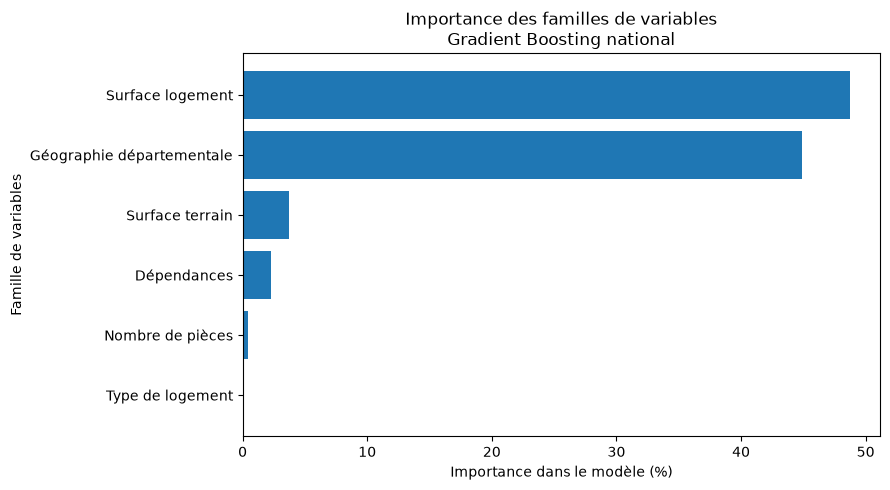

In [133]:
import matplotlib.pyplot as plt

importance_graphique = (
    importance_groupes
    .sort_values("Importance", ascending=True)
)

plt.figure(figsize=(9, 5))

plt.barh(
    importance_graphique["Famille"],
    importance_graphique["Importance"] * 100
)

plt.xlabel("Importance dans le modèle (%)")
plt.ylabel("Famille de variables")
plt.title(
    "Importance des familles de variables\n"
    "Gradient Boosting national"
)

plt.tight_layout()
plt.show()

#### Visualisation de l'importance des variables

La visualisation confirme la forte concentration de l'information prédictive autour de deux familles de variables : la surface du logement et la localisation départementale.

À elles seules, ces deux dimensions représentent près de 94 % de l'importance calculée par le Gradient Boosting. Les caractéristiques complémentaires telles que la surface du terrain, les dépendances ou le nombre de pièces jouent un rôle nettement plus secondaire.

Ces importances décrivent l'utilisation des variables par le modèle et ne doivent pas être interprétées comme des relations causales.

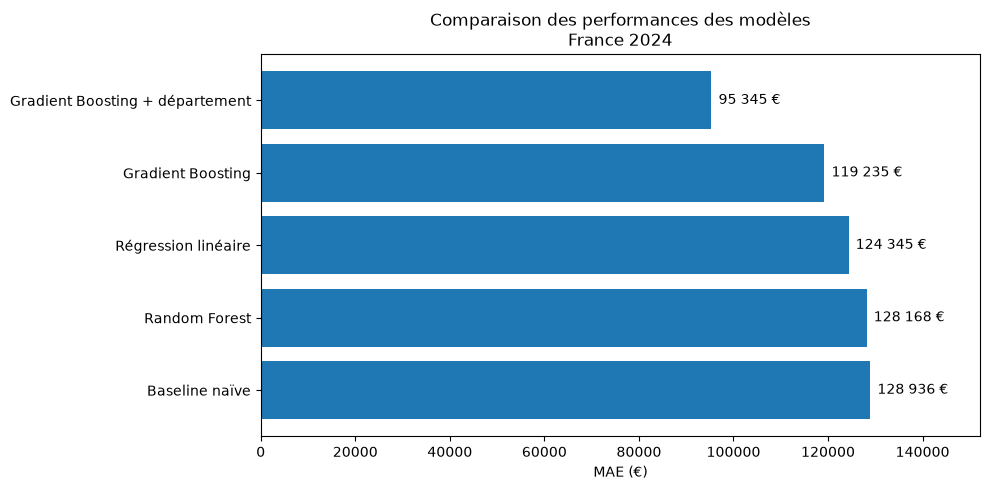

In [139]:
resultats_graphique = (
    resultats_france
    .sort_values("MAE", ascending=True)
)

plt.figure(figsize=(10, 5))

bars = plt.barh(
    resultats_graphique["Modèle"],
    resultats_graphique["MAE"]
)

plt.gca().invert_yaxis()

plt.xlabel("MAE (€)")
plt.title(
    "Comparaison des performances des modèles\n"
    "France 2024"
)

# Afficher la MAE au bout de chaque barre
for bar, valeur in zip(
    bars,
    resultats_graphique["MAE"]
):
    plt.text(
        valeur + 1500,
        bar.get_y() + bar.get_height() / 2,
        f"{valeur:,.0f} €".replace(",", " "),
        va="center"
    )

plt.xlim(
    0,
    resultats_graphique["MAE"].max() * 1.18
)

plt.tight_layout()
plt.show()

#### Comparaison des performances des modèles nationaux

La comparaison des MAE montre que le Gradient Boosting intégrant la localisation départementale obtient les meilleures performances, avec une erreur absolue moyenne d'environ 95 000 €.

Sans information géographique, le Gradient Boosting reste le meilleur modèle selon la MAE avec environ 119 000 €, devant la régression linéaire et le Random Forest.

L'écart important observé après l'ajout du département confirme une nouvelle fois l'importance de la localisation géographique dans la prédiction des prix immobiliers.

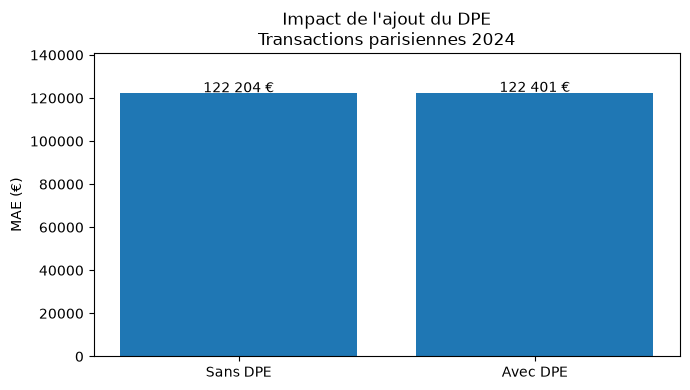

In [140]:
resultats_h3_graphique = resultats_h3.copy()

plt.figure(figsize=(7, 4))

bars = plt.bar(
    resultats_h3_graphique["Configuration"],
    resultats_h3_graphique["MAE"]
)

plt.ylabel("MAE (€)")
plt.title(
    "Impact de l'ajout du DPE\n"
    "Transactions parisiennes 2024"
)

for bar, valeur in zip(
    bars,
    resultats_h3_graphique["MAE"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        valeur + 500,
        f"{valeur:,.0f} €".replace(",", " "),
        ha="center"
    )

plt.ylim(
    0,
    resultats_h3_graphique["MAE"].max() * 1.15
)

plt.tight_layout()
plt.show()

##### Visualisation de l'effet du DPE

La comparaison graphique confirme que l'ajout de l'étiquette DPE ne modifie pratiquement pas l'erreur moyenne du modèle.

La MAE passe d'environ 122 204 € sans DPE à 122 401 € avec DPE. L'information énergétique n'apporte donc pas d'amélioration prédictive sur l'échantillon parisien étudié, ce qui conduit à ne pas soutenir l'hypothèse H3.

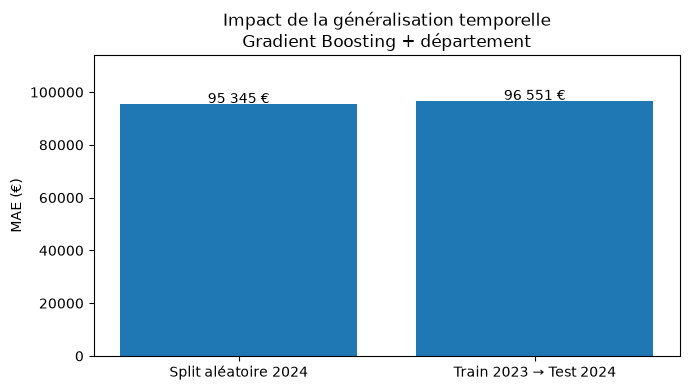

In [141]:
resultats_h4_graphique = resultats_h4.copy()

plt.figure(figsize=(7, 4))

bars = plt.bar(
    resultats_h4_graphique["Configuration"],
    resultats_h4_graphique["MAE"]
)

plt.ylabel("MAE (€)")
plt.title(
    "Impact de la généralisation temporelle\n"
    "Gradient Boosting + département"
)

for bar, valeur in zip(
    bars,
    resultats_h4_graphique["MAE"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        valeur + 500,
        f"{valeur:,.0f} €".replace(",", " "),
        ha="center"
    )

plt.ylim(
    0,
    resultats_h4_graphique["MAE"].max() * 1.18
)

plt.tight_layout()
plt.show()

### Visualisation de la généralisation temporelle

Le modèle entraîné sur les ventes de 2023 puis testé sur celles de 2024 présente une MAE légèrement supérieure à celle obtenue avec un split aléatoire réalisé uniquement sur 2024.

La MAE passe d'environ 95 345 € à 96 551 €. Cette différence reste limitée, ce qui indique que le modèle conserve une capacité de généralisation relativement stable d'une année à l'autre.

L'hypothèse H4 est donc soutenue de manière modérée : la prédiction d'une année future est légèrement plus difficile qu'une évaluation aléatoire au sein d'une même année.

In [142]:
synthese_hypotheses = pd.DataFrame({
    "Hypothèse": [
        "H1",
        "H2",
        "H3",
        "H4"
    ],
    "Question": [
        "Le Gradient Boosting surpasse-t-il les modèles plus simples ?",
        "La géographie améliore-t-elle la prédiction ?",
        "Le DPE améliore-t-il la prédiction ?",
        "La généralisation temporelle est-elle plus difficile ?"
    ],
    "Résultat": [
        "Partiellement soutenue",
        "Soutenue",
        "Non soutenue",
        "Modérément soutenue"
    ]
})

synthese_hypotheses

,Hypothèse,Question,Résultat
0,H1,Le Gradient Boosting surpasse-t-il les modèles...,Partiellement soutenue
1,H2,La géographie améliore-t-elle la prédiction ?,Soutenue
2,H3,Le DPE améliore-t-il la prédiction ?,Non soutenue
3,H4,La généralisation temporelle est-elle plus dif...,Modérément soutenue


## Conclusion des expérimentations

Les expérimentations menées permettent de répondre aux quatre hypothèses formulées au début de l'étude.

**H1 est partiellement soutenue.** Parmi les modèles testés sans information géographique, le Gradient Boosting obtient la meilleure MAE. Toutefois, la régression linéaire conserve de meilleures performances selon certaines métriques, notamment le RMSE et le R². La supériorité du Gradient Boosting n'est donc pas systématique selon le critère considéré.

**H2 est soutenue.** L'ajout de la localisation départementale améliore fortement les performances du Gradient Boosting. À l'échelle nationale, la MAE passe d'environ 119 000 € à 95 000 € et le R² progresse de 0,083 à 0,421. La géographie constitue ainsi une information essentielle pour la prédiction des prix immobiliers.

**H3 n'est pas soutenue.** Sur l'échantillon parisien disposant d'un appariement fiable avec les données DPE, l'ajout de l'étiquette énergétique n'améliore pas les performances du modèle. La MAE passe légèrement de 122 204 € à 122 401 €. Une fois les caractéristiques physiques et géographiques prises en compte, la classe DPE n'apporte donc pas de gain prédictif mesurable dans cette expérience.

**H4 est modérément soutenue.** Le modèle entraîné sur les transactions de 2023 puis évalué sur celles de 2024 présente des performances légèrement inférieures à celles obtenues avec un split aléatoire sur 2024. La MAE augmente de 95 345 € à 96 551 €, ce qui indique une légère dégradation lors de la généralisation à une année future.

Globalement, les résultats montrent que la prédiction des prix immobiliers dépend principalement de la surface du logement et de sa localisation géographique. L'analyse des importances du meilleur modèle confirme cette observation : ces deux familles concentrent à elles seules près de 94 % de l'importance calculée par le Gradient Boosting.

# Limites de l'étude

Malgré les résultats obtenus, plusieurs limites doivent être prises en compte dans l'interprétation de cette étude.

### 1. Précision géographique limitée à l'échelle nationale

Dans le modèle national, la localisation est représentée principalement par le département. Cette granularité reste relativement large et ne permet pas de capturer les fortes variations de prix pouvant exister entre communes, quartiers ou rues d'un même département.

L'utilisation d'informations géographiques plus fines, telles que les coordonnées géographiques, la commune ou la proximité avec certains équipements, pourrait améliorer les performances du modèle.

### 2. Expérience DPE limitée à Paris

L'apport du DPE a été évalué uniquement sur les transactions parisiennes pour lesquelles un appariement suffisamment fiable entre DVF+ et les diagnostics énergétiques a pu être réalisé.

La conclusion selon laquelle le DPE n'améliore pas les prédictions ne peut donc pas être généralisée directement à l'ensemble du marché immobilier français. L'impact de la performance énergétique pourrait être différent dans d'autres territoires.

### 3. Appariement probabiliste entre DVF+ et DPE

Les bases DVF+ et DPE ne disposent pas d'un identifiant commun permettant de relier directement une transaction à son diagnostic énergétique.

L'appariement repose donc sur plusieurs critères : une distance géographique maximale de 50 mètres, un DPE établi avant la date de vente et un écart de surface inférieur ou égal à 10 %.

Cette méthodologie permet d'obtenir un niveau de correspondance élevé, mais elle ne garantit pas que chaque diagnostic sélectionné corresponde avec certitude au logement effectivement vendu.

### 4. Période temporelle limitée

La majorité des expérimentations repose sur les transactions réalisées en 2024. Un test supplémentaire a été réalisé en entraînant le modèle sur 2023 puis en l'évaluant sur 2024, mais l'étude ne couvre pas plusieurs cycles du marché immobilier.

L'intégration de plusieurs années successives permettrait de mieux évaluer la robustesse temporelle des modèles et leur capacité à s'adapter aux évolutions du marché.

### 5. Optimisation limitée des modèles

Les modèles ont été comparés avec des configurations relativement simples afin de conserver un protocole expérimental homogène et interprétable.

Une recherche plus approfondie des hyperparamètres, par validation croisée ou optimisation automatique, pourrait améliorer les performances du Random Forest et du Gradient Boosting. D'autres approches telles que XGBoost, LightGBM ou CatBoost pourraient également être étudiées.

### 6. Variables explicatives encore limitées

Les données utilisées décrivent principalement les caractéristiques physiques, géographiques et énergétiques des logements.

D'autres facteurs susceptibles d'influencer fortement les prix ne sont pas intégrés, notamment la proximité des transports, des écoles et des commerces, les caractéristiques socio-économiques du quartier, l'étage, la présence d'un ascenseur, l'état du logement ou encore la qualité de son environnement immédiat.

L'ajout de ces informations pourrait permettre de mieux expliquer les différences de prix entre des logements présentant des caractéristiques physiques similaires.

In [ ]:
resultats_france.to_csv(
    "../reports/resultats_modeles_france.csv",
    index=False
)

resultats_h3.to_csv(
    "../reports/resultats_h3_dpe.csv",
    index=False
)

resultats_h4.to_csv(
    "../reports/resultats_h4_temporel.csv",
    index=False
)

synthese_hypotheses.to_csv(
    "../reports/synthese_hypotheses.csv",
    index=False
)

importance_groupes.to_csv(
    "../reports/importance_variables.csv",
    index=False
)

print("Résultats finaux sauvegardés.")

Résultats finaux sauvegardés.


: 